In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

In [35]:
df = pd.read_csv(r"Dataset/student_performance_data.CSV")


In [36]:
df.head()

,Student_ID,Gender,Study_Hours_per_Week,Attendance_Rate,Past_Exam_Scores,Parental_Education_Level,Internet_Access_at_Home,Extracurricular_Activities,Final_Exam_Score,Pass_Fail
0,S00001,Male,31.0,68.3,NaN,High School,Yes,Yes,63,Pass
1,S00002,Male,16.0,78.2,73.0,PhD,No,No,50,Fail
2,S00003,Female,21.0,87.5,74.0,PhD,Yes,No,55,Fail
3,S00004,Female,27.0,92.1,99.0,Bachelors,No,NaN,65,Pass
4,S00005,Female,37.0,98.7,63.0,Masters,No,Yes,70,Pass


In [37]:
df.head(10)

,Student_ID,Gender,Study_Hours_per_Week,Attendance_Rate,Past_Exam_Scores,Parental_Education_Level,Internet_Access_at_Home,Extracurricular_Activities,Final_Exam_Score,Pass_Fail
0,S00001,Male,31.0,68.3,NaN,High School,Yes,Yes,63,Pass
1,S00002,Male,16.0,78.2,73.0,PhD,No,No,50,Fail
2,S00003,Female,21.0,87.5,74.0,PhD,Yes,No,55,Fail
3,S00004,Female,27.0,92.1,99.0,Bachelors,No,NaN,65,Pass
4,S00005,Female,37.0,98.7,63.0,Masters,No,Yes,70,Pass
5,S00006,Male,NaN,NaN,77.0,Masters,Yes,No,61,Pass
6,S00007,Male,24.0,89.4,95.0,High School,NaN,Yes,61,Pass
7,S00008,Male,31.0,50.7,78.0,Masters,No,No,50,Fail
8,S00009,Female,34.0,80.9,94.0,PhD,No,Yes,65,Pass
9,S00010,Male,27.0,65.5,86.0,High School,NaN,No,55,Fail


In [38]:
df.columns

Index(['Student_ID', 'Gender', 'Study_Hours_per_Week', 'Attendance_Rate',
       'Past_Exam_Scores', 'Parental_Education_Level',
       'Internet_Access_at_Home', 'Extracurricular_Activities',
       'Final_Exam_Score', 'Pass_Fail'],
      dtype='object')

In [39]:
df.size

100000

In [40]:
df.shape

(10000, 10)

In [41]:
df.describe()

,Study_Hours_per_Week,Attendance_Rate,Past_Exam_Scores,Final_Exam_Score
count,9200.000000,9200.000000,9200.000000,10000.000000
mean,26.111739,78.048435,77.836087,58.989500
std,8.930279,14.030844,14.473793,7.072382
min,10.000000,50.000000,50.000000,50.000000
25%,19.000000,67.400000,66.000000,52.000000
50%,27.000000,79.400000,79.000000,59.000000
75%,34.000000,89.800000,91.000000,64.000000
max,39.000000,100.000000,100.000000,77.000000


In [42]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Student_ID                  10000 non-null  object 
 1   Gender                      9200 non-null   object 
 2   Study_Hours_per_Week        9200 non-null   float64
 3   Attendance_Rate             9200 non-null   float64
 4   Past_Exam_Scores            9200 non-null   float64
 5   Parental_Education_Level    10000 non-null  object 
 6   Internet_Access_at_Home     9200 non-null   object 
 7   Extracurricular_Activities  9200 non-null   object 
 8   Final_Exam_Score            10000 non-null  int64  
 9   Pass_Fail                   10000 non-null  object 
dtypes: float64(3), int64(1), object(6)
memory usage: 781.4+ KB


In [43]:
#Finding the missing values
df.isnull().sum()

Student_ID                      0
Gender                        800
Study_Hours_per_Week          800
Attendance_Rate               800
Past_Exam_Scores              800
Parental_Education_Level        0
Internet_Access_at_Home       800
Extracurricular_Activities    800
Final_Exam_Score                0
Pass_Fail                       0
dtype: int64

In [44]:
## Finding the percentage of missing values
df.isnull().mean()*100

Student_ID                    0.0
Gender                        8.0
Study_Hours_per_Week          8.0
Attendance_Rate               8.0
Past_Exam_Scores              8.0
Parental_Education_Level      0.0
Internet_Access_at_Home       8.0
Extracurricular_Activities    8.0
Final_Exam_Score              0.0
Pass_Fail                     0.0
dtype: float64

In [45]:
## Total missing values
print("Total missing values:",df.isnull().sum().sum())

Total missing values: 4800


In [46]:
## Analyze distribution
#Identify the numeric columns

num_cols=df.select_dtypes(include=np.number).columns
print(num_cols)

Index(['Study_Hours_per_Week', 'Attendance_Rate', 'Past_Exam_Scores',
       'Final_Exam_Score'],
      dtype='object')


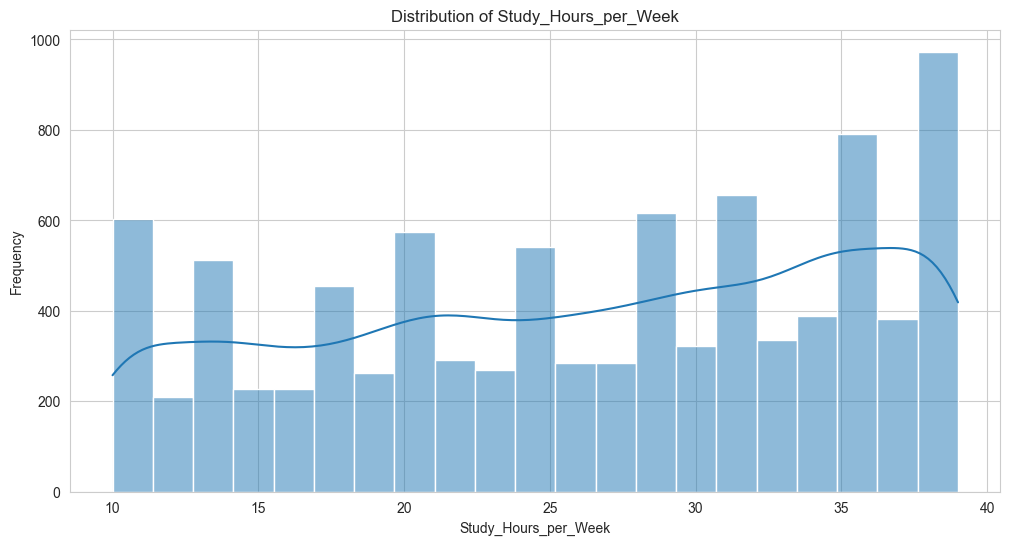

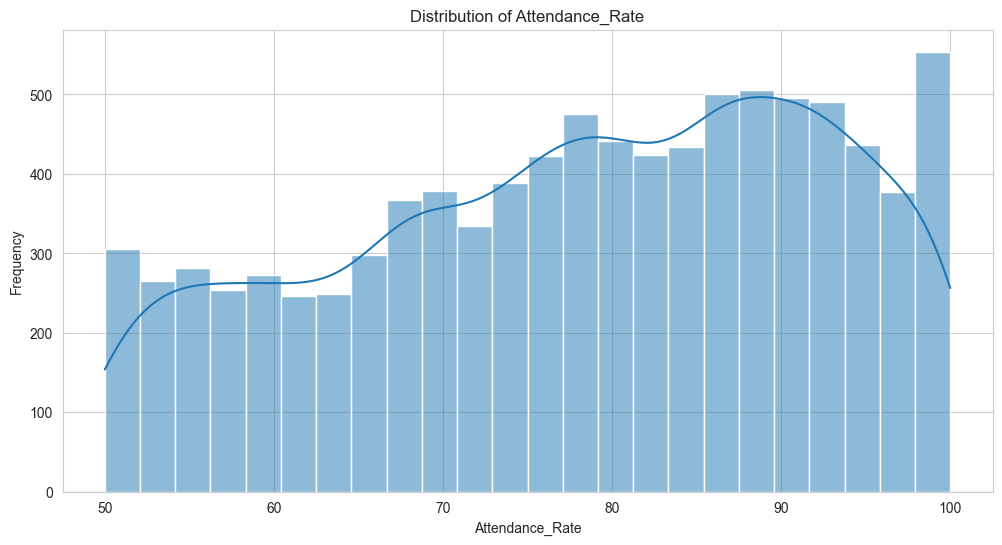

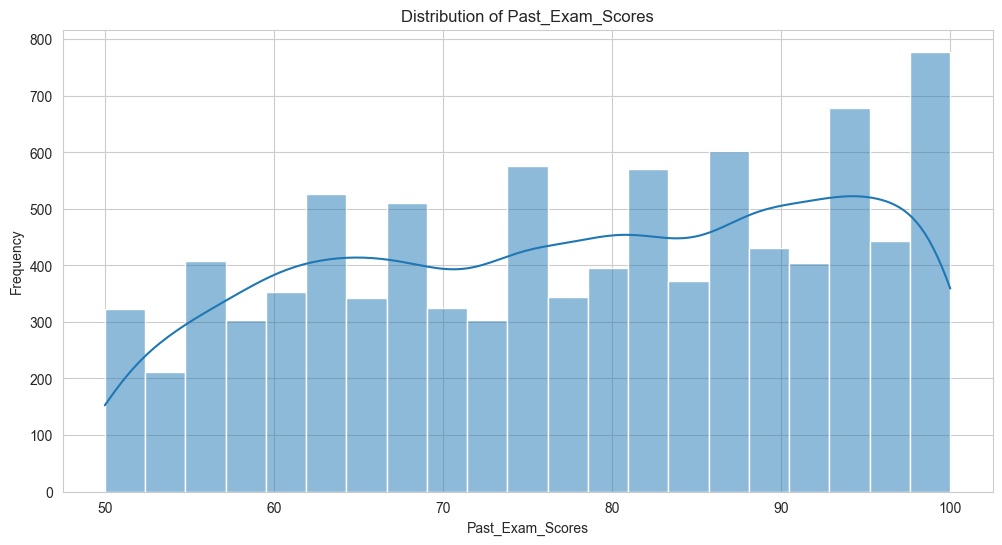

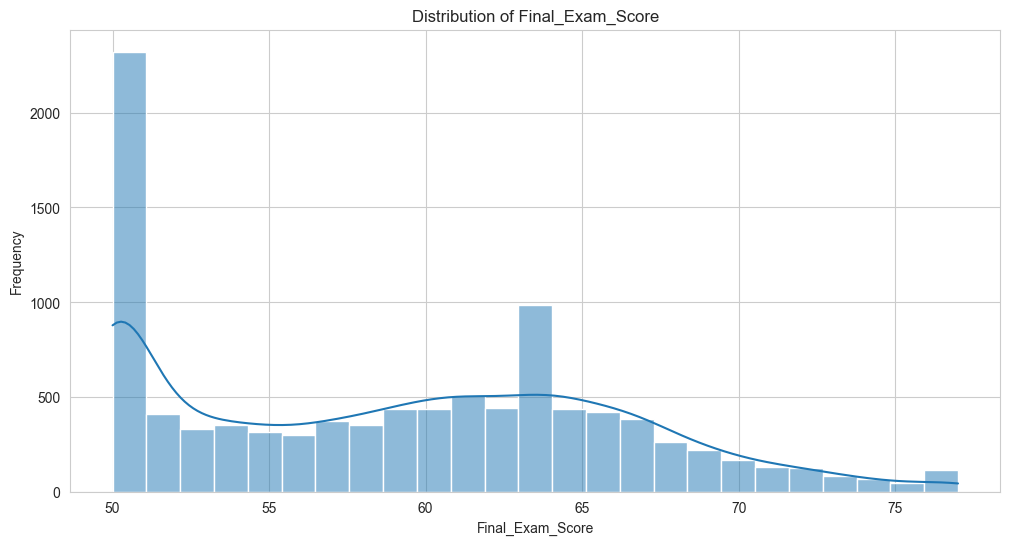

In [47]:
## Histogram
for col in num_cols:
    plt.figure(figsize=(12,6))
    sns.histplot(df[col],kde=True)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

In [48]:
## Calculate the skewness
for col in num_cols:
    print(col,":",df[col].skew())

Study_Hours_per_Week : -0.23737357793833228
Attendance_Rate : -0.29808350847639076
Past_Exam_Scores : -0.17664744503233967
Final_Exam_Score : 0.2987190068891565


- Skewness value	Distribution
1. Around 0	Approximately symmetrical
2. -0.5 to 0	Slightly left-skewed
3. 0 to 0.5	Slightly right-skewed
4. -1 to -0.5	Moderately left-skewed
5. 0.5 to 1	Moderately right-skewed
6. Below -1 or above 1	Highly skewed

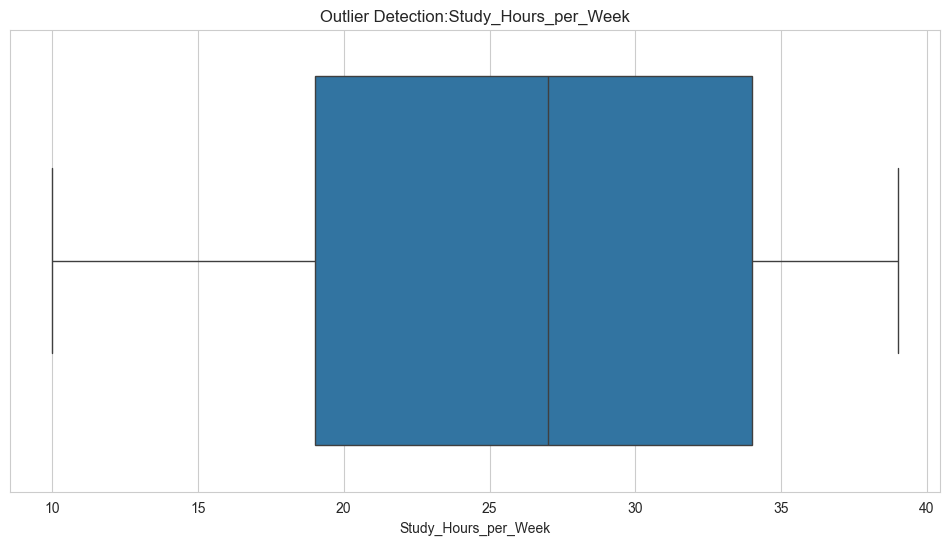

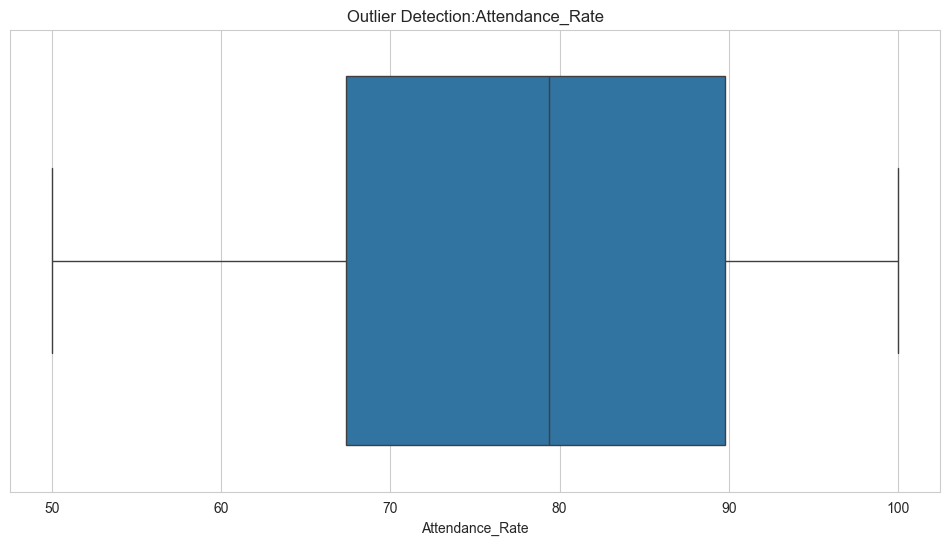

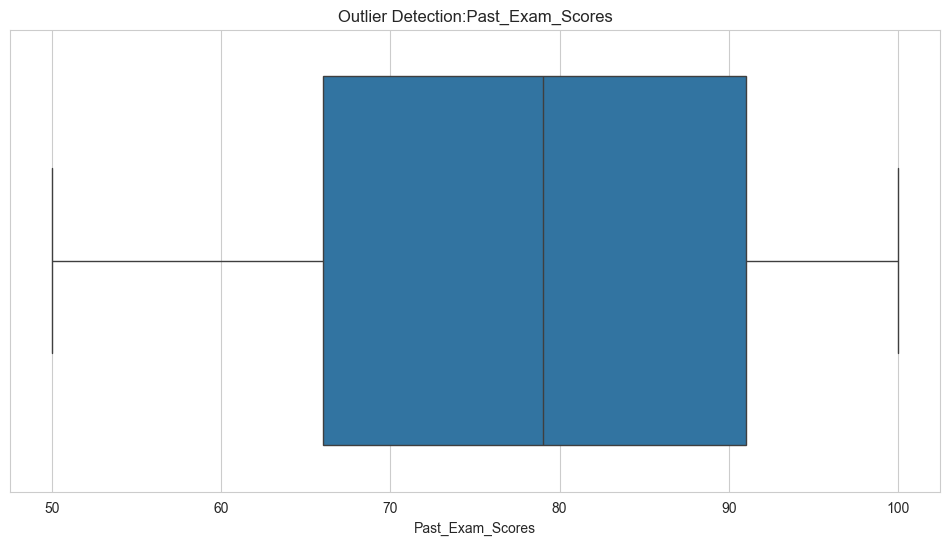

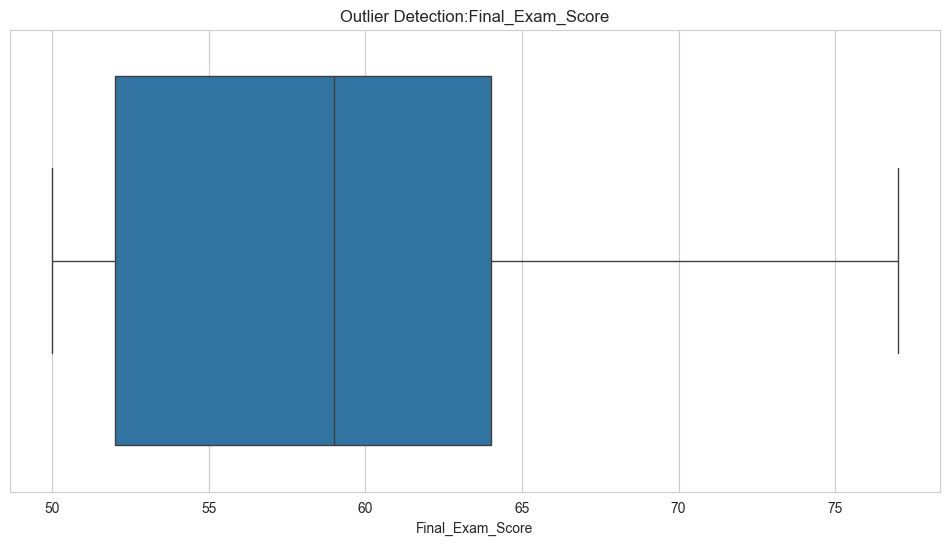

In [49]:
## Detect outliers using boxplot
for col in num_cols:
    plt.figure(figsize=(12,6))
    sns.boxplot(x=df[col])
    plt.title(f"Outlier Detection:{col}")
    plt.show()

- From the above graph we can say that there are no outliers within the given features.

In [50]:
## Identify outlier using IQR

for col in num_cols:
    Q1=df[col].quantile(0.25)
    Q3=df[col].quantile(0.75)

    IQR=Q3-Q1

    lower=Q1-1.5*IQR
    upper=Q3+1.5*IQR

    outliers=df[
        (df[col]<lower)|
        (df[col]>upper)
    ]
    print("\n Columns:",col)
    print("Lower Limit:",lower)
    print("Upper Limit",upper)
    print("Outliers:",len(outliers))


 Columns: Study_Hours_per_Week
Lower Limit: -3.5
Upper Limit 56.5
Outliers: 0

 Columns: Attendance_Rate
Lower Limit: 33.80000000000002
Upper Limit 123.39999999999998
Outliers: 0

 Columns: Past_Exam_Scores
Lower Limit: 28.5
Upper Limit 128.5
Outliers: 0

 Columns: Final_Exam_Score
Lower Limit: 34.0
Upper Limit 82.0
Outliers: 0


#### All four numerical columns have relatively low skewness, and the IQR method identifies no outliers.

### EDA (Exploratory Data Analysis)

#### `Fill numerical missing values`


In [51]:
df['Study_Hours_per_Week']=df['Study_Hours_per_Week'].fillna(df['Study_Hours_per_Week'].mean())
df['Attendance_Rate']=df['Attendance_Rate'].fillna(df['Attendance_Rate'].mean())
df['Past_Exam_Scores']=df['Past_Exam_Scores'].fillna(df['Past_Exam_Scores'].mean())

### `Fill categorical missing values`

In [52]:
df.isnull().sum()

Student_ID                      0
Gender                        800
Study_Hours_per_Week            0
Attendance_Rate                 0
Past_Exam_Scores                0
Parental_Education_Level        0
Internet_Access_at_Home       800
Extracurricular_Activities    800
Final_Exam_Score                0
Pass_Fail                       0
dtype: int64

- -	The mean is pulled by extreme values; the median is not. So if column is skewed or has outliers, use the median. If the column is roughly symmetrical with no outliers, the mean and median are almost the same, so the mean is fine.

In [53]:
categorical_cols=['Gender',
                  'Internet_Access_at_Home',
                  'Extracurricular_Activities']
for col in categorical_cols:
    df[col]=df[col].fillna(df[col].mode()[0])

In [54]:
print("Missing values after imputation:")
print(df.isnull().sum())
print("Total missing values:",df.isnull().sum().sum())

Missing values after imputation:
Student_ID                    0
Gender                        0
Study_Hours_per_Week          0
Attendance_Rate               0
Past_Exam_Scores              0
Parental_Education_Level      0
Internet_Access_at_Home       0
Extracurricular_Activities    0
Final_Exam_Score              0
Pass_Fail                     0
dtype: int64
Total missing values: 0


In [55]:
## Save cleaned dataset
df.to_csv("student_performance_cleaned.csv",index=False)
print("Cleaned dataset saved successfully")

Cleaned dataset saved successfully


In [56]:
original=pd.read_csv(r"Dataset/student_performance_data.csv")
cleaned=pd.read_csv(r"Dataset/student_performance_cleaned.csv")

print("Before cleaning:")
print(original.describe())

print("\n After cleaning:")
print(cleaned.describe())

Before cleaning:
       Study_Hours_per_Week  Attendance_Rate  Past_Exam_Scores  \
count           9200.000000      9200.000000       9200.000000   
mean              26.111739        78.048435         77.836087   
std                8.930279        14.030844         14.473793   
min               10.000000        50.000000         50.000000   
25%               19.000000        67.400000         66.000000   
50%               27.000000        79.400000         79.000000   
75%               34.000000        89.800000         91.000000   
max               39.000000       100.000000        100.000000   

       Final_Exam_Score  
count      10000.000000  
mean          58.989500  
std            7.072382  
min           50.000000  
25%           52.000000  
50%           59.000000  
75%           64.000000  
max           77.000000  

 After cleaning:
       Study_Hours_per_Week  Attendance_Rate  Past_Exam_Scores  \
count          10000.000000     10000.000000      10000.000000   
mean

In [57]:
df=pd.read_csv(r'Dataset/student_performance_cleaned.csv')
df.head()

,Student_ID,Gender,Study_Hours_per_Week,Attendance_Rate,Past_Exam_Scores,Parental_Education_Level,Internet_Access_at_Home,Extracurricular_Activities,Final_Exam_Score,Pass_Fail
0,S00001,Male,31.0,68.3,77.836087,High School,Yes,Yes,63,Pass
1,S00002,Male,16.0,78.2,73.000000,PhD,No,No,50,Fail
2,S00003,Female,21.0,87.5,74.000000,PhD,Yes,No,55,Fail
3,S00004,Female,27.0,92.1,99.000000,Bachelors,No,No,65,Pass
4,S00005,Female,37.0,98.7,63.000000,Masters,No,Yes,70,Pass


In [58]:
## Identify duplicate records
duplicates=df.duplicated()
print(duplicates)

0       False
1       False
2       False
3       False
4       False
        ...  
9995    False
9996    False
9997    False
9998    False
9999    False
Length: 10000, dtype: bool


In [59]:
duplicate_count=df.duplicated().sum()
print(f"Total duplicated rows: {duplicate_count}")

Total duplicated rows: 0


- The count is 0, so there are no fully duplicated rows

In [60]:
df.dtypes

Student_ID                     object
Gender                         object
Study_Hours_per_Week          float64
Attendance_Rate               float64
Past_Exam_Scores              float64
Parental_Education_Level       object
Internet_Access_at_Home        object
Extracurricular_Activities     object
Final_Exam_Score                int64
Pass_Fail                      object
dtype: object

### Convert data type conversion

In [61]:
df['Student_ID'] = df['Student_ID'].astype(str)


In [62]:
categorical_cols = [
    'Gender',
    'Parental_Education_Level',
    'Internet_Access_at_Home',
    'Extracurricular_Activities'
]

for col in categorical_cols:
    df[col] = df[col].astype('category')

print(df[categorical_cols + ['Pass_Fail']].dtypes)

Gender                        category
Parental_Education_Level      category
Internet_Access_at_Home       category
Extracurricular_Activities    category
Pass_Fail                       object
dtype: object


In [63]:
print(num_cols)

Index(['Study_Hours_per_Week', 'Attendance_Rate', 'Past_Exam_Scores',
       'Final_Exam_Score'],
      dtype='object')


In [64]:
print(original.isnull().sum())

Student_ID                      0
Gender                        800
Study_Hours_per_Week          800
Attendance_Rate               800
Past_Exam_Scores              800
Parental_Education_Level        0
Internet_Access_at_Home       800
Extracurricular_Activities    800
Final_Exam_Score                0
Pass_Fail                       0
dtype: int64


In [65]:
## Pass Fail Value count
result_counts=df['Pass_Fail'].value_counts()
result_counts


Pass_Fail
Fail    5190
Pass    4810
Name: count, dtype: int64

In [66]:
total_students=df["Student_ID"].nunique()
total_students

10000

In [67]:
pass_count=result_counts.get("Pass",0)
fail_count=result_counts.get("Fail",0)
print("Total students",total_students)
print(f"The total number of students pass count is: {pass_count}")
print(f"The total number of students Fail count is: {fail_count}")

Total students 10000
The total number of students pass count is: 4810
The total number of students Fail count is: 5190


In [68]:
## Pass and Fail percentage
pass_percentage=(pass_count/total_students)*100
faile_percentage=(fail_count/total_students)*100
print(f"Pass_percentage is {pass_percentage}")
print(f"Faile_percentage is {faile_percentage}")

Pass_percentage is 48.1
Faile_percentage is 51.9


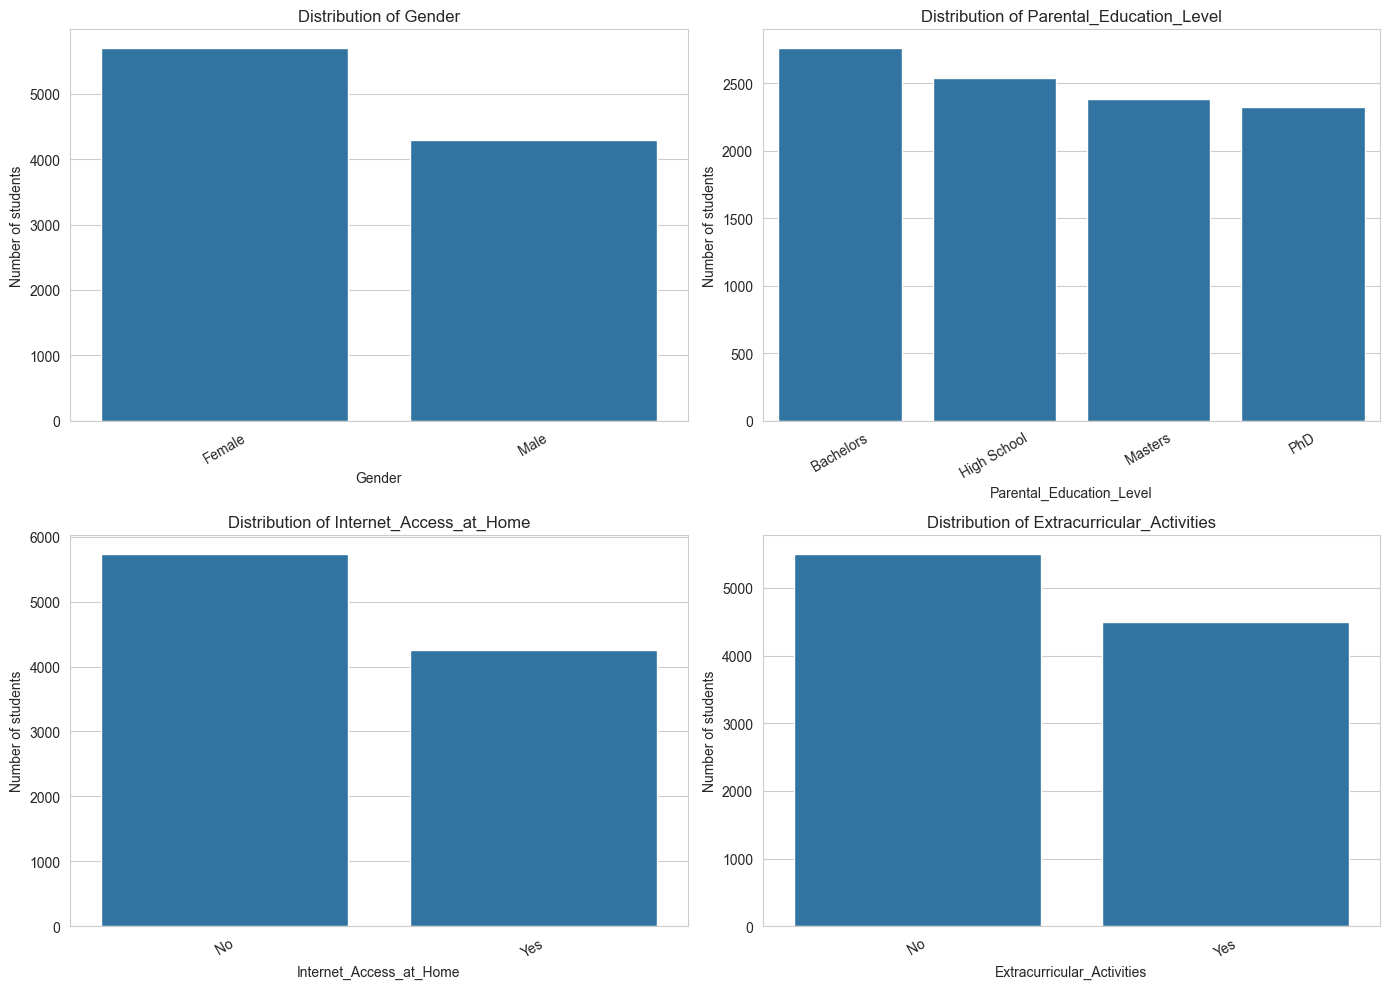

In [69]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_style("whitegrid")

categorical_cols = [
    'Gender',
    'Parental_Education_Level',
    'Internet_Access_at_Home',
    'Extracurricular_Activities'
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, col in zip(axes, categorical_cols):
    sns.countplot(
        x=col,
        data=df,
        order=df[col].value_counts().index,
        ax=ax
    )
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Number of students")
    ax.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig(
    "categorical_distributions.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

### Explanation of the categorical distribution plot

- `categorical_cols`: stores the four categorical feature names.
- `plt.subplots(2, 2, figsize=(14, 10))`: creates a 2-row by 2-column layout with a figure size of 14 × 10 inches.
- `axes.flatten()`: converts the 2D axes array into a one-dimensional array so each plot can be addressed in the loop.
- `zip(axes, categorical_cols)`: pairs each subplot with one categorical feature.
- `sns.countplot()`: counts the observations in each category.
- `value_counts().index`: orders categories from most frequent to least frequent.
- `tick_params(..., rotation=30)`: rotates category labels for readability.
- `plt.tight_layout()`: reduces overlap between chart elements.


### Compare categorical columns against Pass_Fail

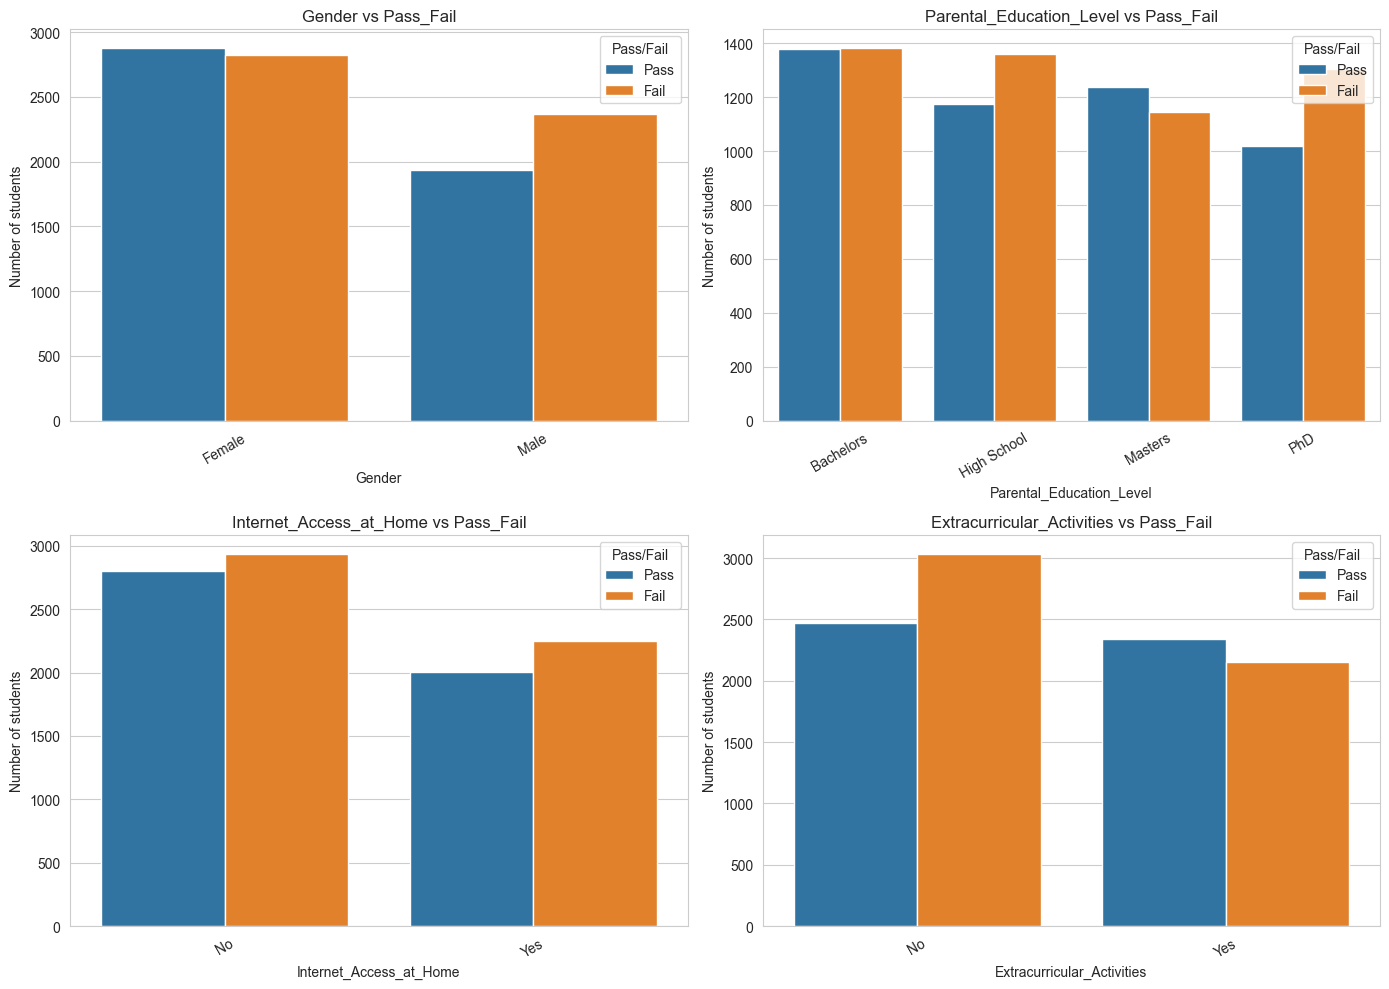

In [70]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, col in zip(axes, categorical_cols):
    sns.countplot(
        x=col,
        hue="Pass_Fail",
        data=df,
        ax=ax
    )
    ax.set_title(f"{col} vs Pass_Fail")
    ax.set_xlabel(col)
    ax.set_ylabel("Number of students")
    ax.tick_params(axis='x', rotation=30)
    ax.legend(title="Pass/Fail")

plt.tight_layout()
plt.savefig(
    "categorical_features_vs_pass_fail.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

- **Gender:** Female students have a pass percentage of **50.46%**, compared with **44.97%** for male students.
- **Parental Education Level:** The Masters category has the highest pass percentage (**51.99%**), while the PhD category has the lowest (**43.80%**).
- **Internet Access:** Students without home internet have a pass percentage of **48.82%**, compared with **47.12%** for students with home internet. The difference is small.
- **Extracurricular Activities:** **52.08%** of students who participate passed, compared with **44.85%** of students who do not participate. This is an association, not proof of causation.

#### Calculate pass percentage for each category

In [71]:
for col in categorical_cols:
    print("\nPass Percentage by",col)
    pass_percentage=pd.crosstab(
        df[col],
        df['Pass_Fail'],
        normalize='index'
    )*100

    print(pass_percentage.round(2))


Pass Percentage by Gender
Pass_Fail   Fail   Pass
Gender                 
Female     49.54  50.46
Male       55.03  44.97

Pass Percentage by Parental_Education_Level
Pass_Fail                  Fail   Pass
Parental_Education_Level              
Bachelors                 50.07  49.93
High School               53.61  46.39
Masters                   48.01  51.99
PhD                       56.20  43.80

Pass Percentage by Internet_Access_at_Home
Pass_Fail                 Fail   Pass
Internet_Access_at_Home              
No                       51.18  48.82
Yes                      52.88  47.12

Pass Percentage by Extracurricular_Activities
Pass_Fail                    Fail   Pass
Extracurricular_Activities              
No                          55.15  44.85
Yes                         47.92  52.08


- pd.crosstab() creates a frequency table between two columns.
- normalize='index' calculates percentages within each category.

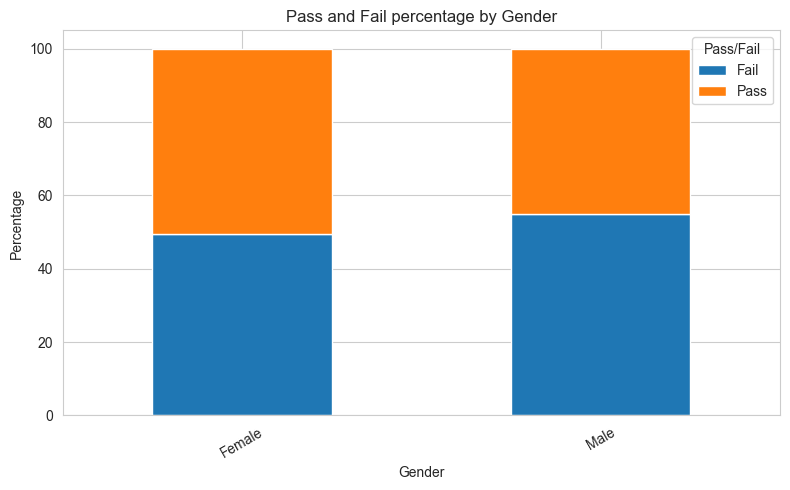

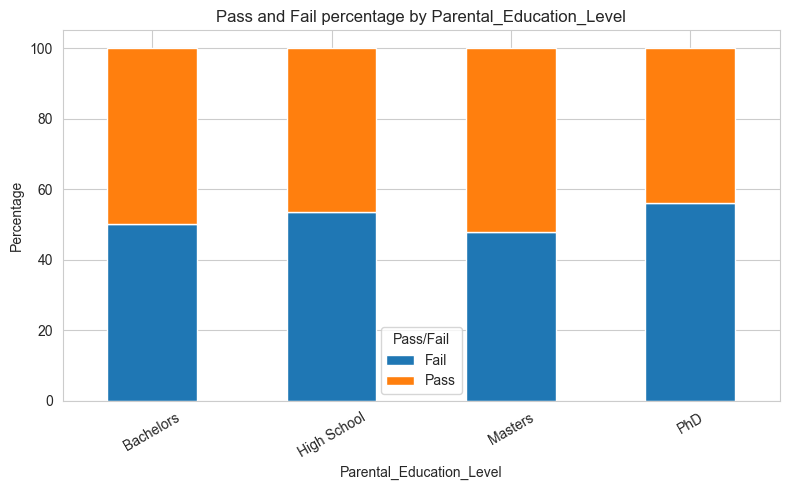

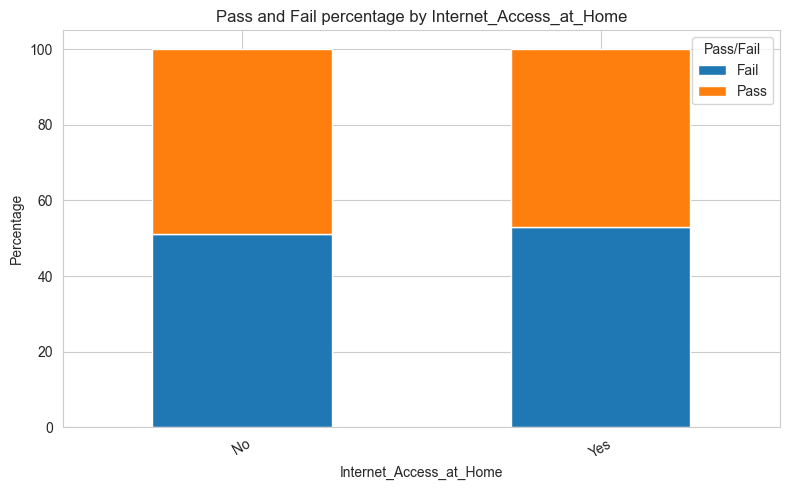

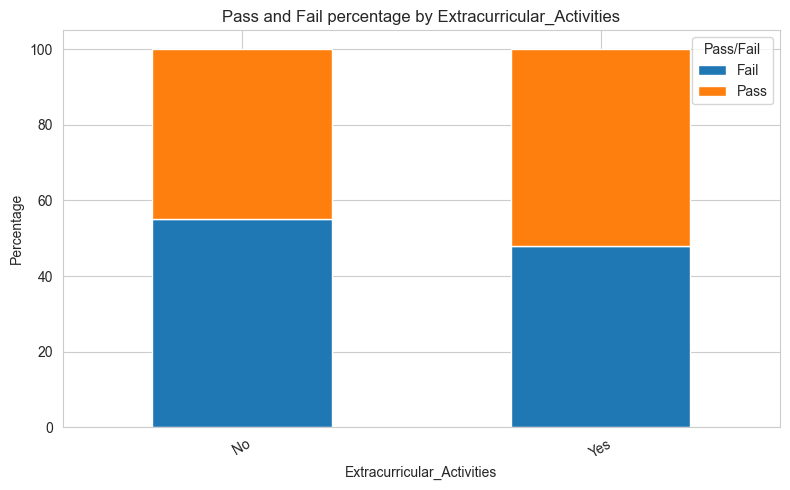

In [72]:
for col in categorical_cols:
    result = pd.crosstab(
        df[col],
        df['Pass_Fail'],
        normalize='index'
    ) * 100

    ax = result.plot(
        kind='bar',
        figsize=(8, 5),
        stacked=True
    )
    ax.set_title(f"Pass and Fail percentage by {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Percentage")
    ax.tick_params(axis='x', rotation=30)
    ax.legend(title="Pass/Fail")

    plt.tight_layout()
    plt.savefig(
        f"pass_fail_percentage_by_{col}.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()

**Extracurricular Activities:** The crosstab shows that **52.08%** of students who participate in extracurricular activities passed, compared with **44.85%** of students who do not participate. The corresponding Fail percentages are **47.92%** for Yes and **55.15%** for No. This is an observed association in this dataset; it does not show that extracurricular participation causes students to pass.

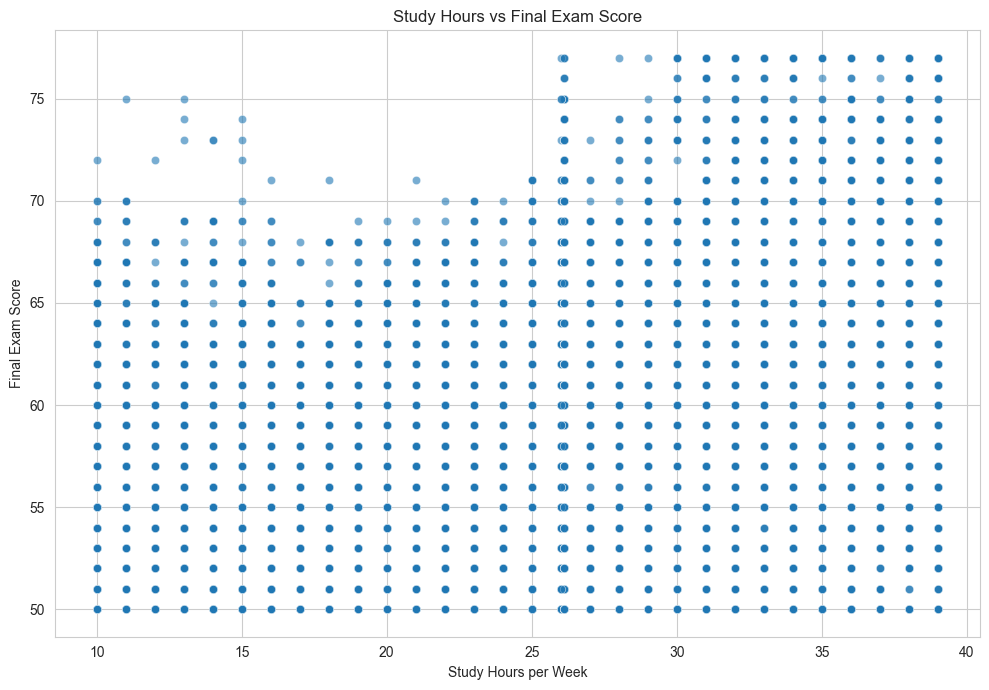

In [73]:
plt.figure(figsize=(10, 7))
sns.scatterplot(
    x='Study_Hours_per_Week',
    y='Final_Exam_Score',
    data=df,
    alpha=0.6
)
plt.title('Study Hours vs Final Exam Score')
plt.xlabel('Study Hours per Week')
plt.ylabel('Final Exam Score')
plt.tight_layout()
plt.savefig("study_hours_vs_score.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

**Scatterplot interpretation:** Study hours have a positive, moderate correlation with Final Exam Score (**r = 0.409991**, approximately **0.41**). The scatterplot is consistent with a general upward relationship: students reporting more study hours tend to have higher final scores in this dataset. This is an association, not evidence that study hours alone cause higher scores.

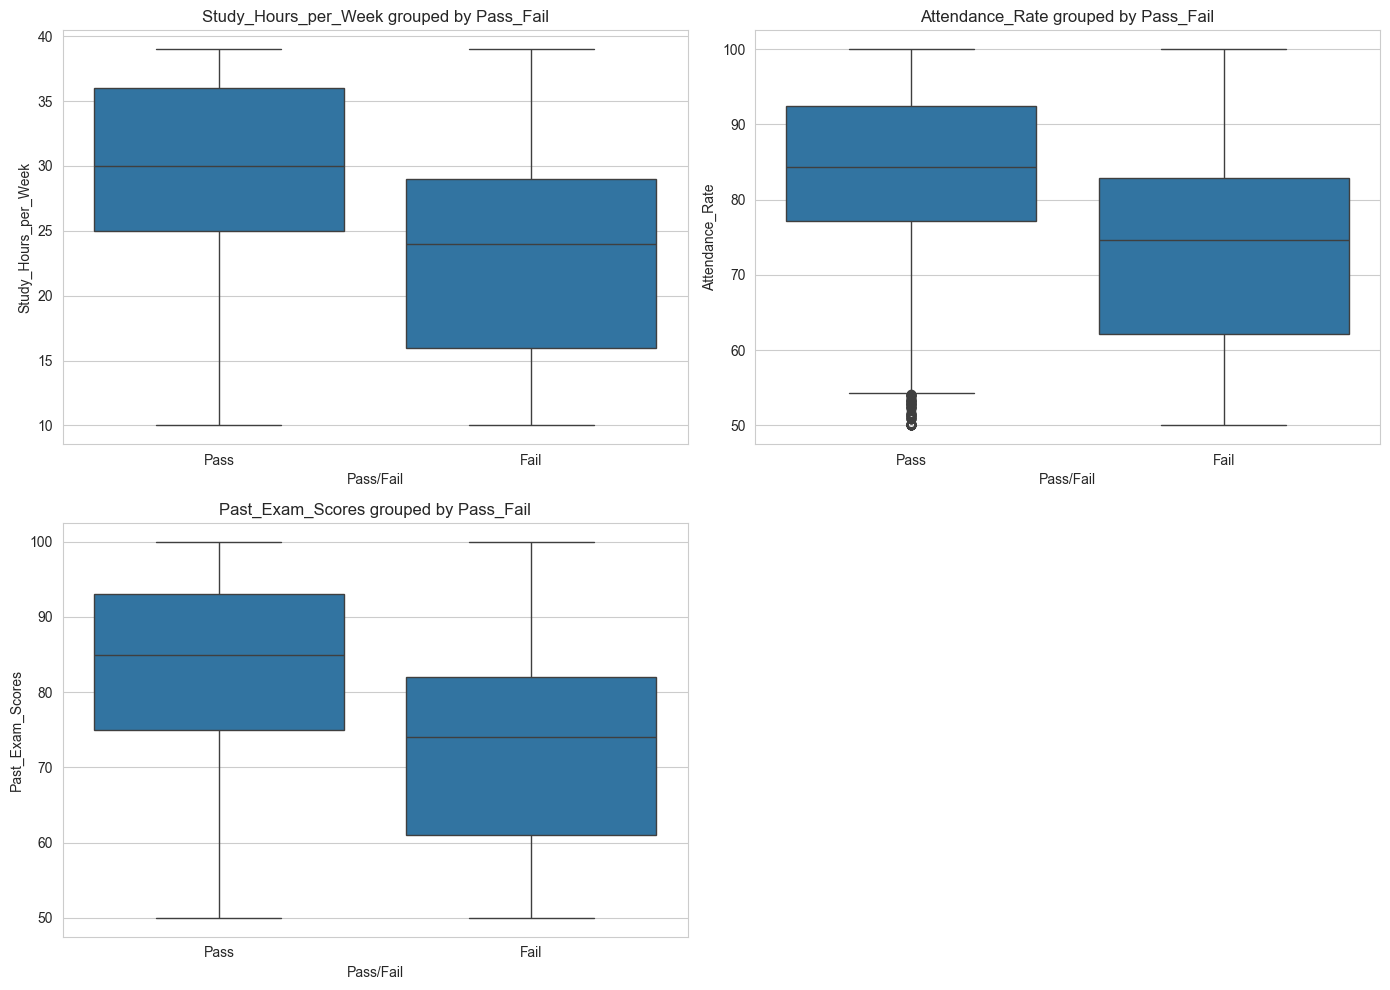

In [74]:
numeric_features = [
    'Study_Hours_per_Week',
    'Attendance_Rate',
    'Past_Exam_Scores'
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, col in zip(axes, numeric_features):
    sns.boxplot(
        x='Pass_Fail',
        y=col,
        data=df,
        ax=ax
    )
    ax.set_title(f'{col} grouped by Pass_Fail')
    ax.set_xlabel('Pass/Fail')
    ax.set_ylabel(col)

# Hide the unused fourth subplot (three numerical predictors).
for ax in axes[len(numeric_features):]:
    ax.set_visible(False)

plt.tight_layout()
plt.savefig("numeric_boxplots.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

In [75]:
# Exact medians and interquartile ranges for the three model predictors.
# Run this cell to obtain the precise values behind the boxplot interpretation.
numeric_eda_summary = (
    df.groupby("Pass_Fail")[numeric_features]
      .agg(["median", lambda x: x.quantile(0.25), lambda x: x.quantile(0.75)])
)

numeric_eda_summary.columns = [
    f"{feature}_{stat_name}"
    for feature, stat_name in numeric_eda_summary.columns
]
numeric_eda_summary = numeric_eda_summary.rename(columns={
    col: col.replace("<lambda_0>", "Q1").replace("<lambda_1>", "Q3")
    for col in numeric_eda_summary.columns
})
display(numeric_eda_summary.round(2))


,Study_Hours_per_Week_median,Study_Hours_per_Week_Q1,Study_Hours_per_Week_Q3,Attendance_Rate_median,Attendance_Rate_Q1,Attendance_Rate_Q3,Past_Exam_Scores_median,Past_Exam_Scores_Q1,Past_Exam_Scores_Q3
Pass_Fail,,,,,,,,,
Fail,24.0,16.0,29.0,74.6,62.10,82.9,74.0,61.0,82.0
Pass,30.0,25.0,36.0,84.4,77.12,92.4,85.0,75.0,93.0


**Boxplot interpretation:** In the saved boxplots, the approximate medians are **24 vs 30 study hours per week** (Fail vs Pass), **74.5% vs 84.3% attendance** (Fail vs Pass), and **74 vs 85 past-exam score points** (Fail vs Pass). The Pass group has a higher median for all three predictors. These values are approximate readings from the plotted medians; the summary-statistics cell below calculates the exact medians and interquartile ranges from the dataset. The final-exam score is deliberately excluded from model predictors because it defines the target.

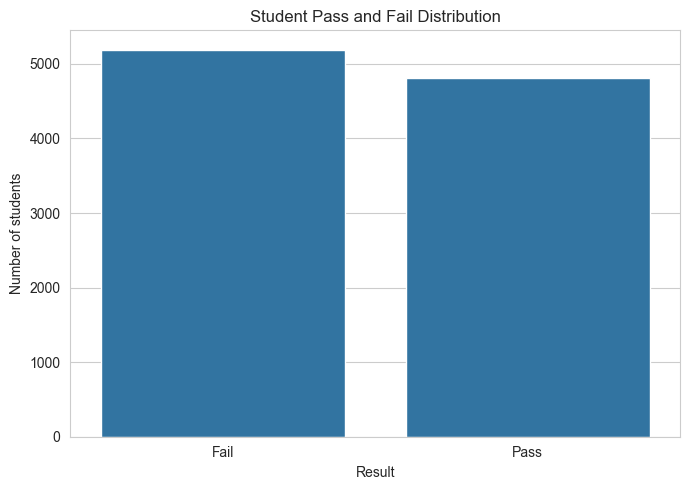

In [76]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x='Pass_Fail', order=['Fail', 'Pass'])
plt.title("Student Pass and Fail Distribution")
plt.xlabel("Result")
plt.ylabel("Number of students")
plt.tight_layout()
plt.savefig("pass_fail_distribution.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

- The countplot shows the number of students in each outcome category. Compare the bar heights to determine whether the Fail or Pass class has more students.

In [77]:
num_cols

Index(['Study_Hours_per_Week', 'Attendance_Rate', 'Past_Exam_Scores',
       'Final_Exam_Score'],
      dtype='object')

In [78]:
correlation = df[
    num_cols
].corr()

score_correlation = correlation['Final_Exam_Score'].drop(
    'Final_Exam_Score'
)

print("Correlation with Final Exam Score:")
print(score_correlation.sort_values(ascending=False))

print("\nStrongest relationship:")
print(score_correlation.abs().idxmax())

print("\nWeakest relationship:")
print(score_correlation.abs().idxmin())

Correlation with Final Exam Score:
Attendance_Rate         0.441047
Study_Hours_per_Week    0.409991
Past_Exam_Scores        0.393707
Name: Final_Exam_Score, dtype: float64

Strongest relationship:
Attendance_Rate

Weakest relationship:
Past_Exam_Scores


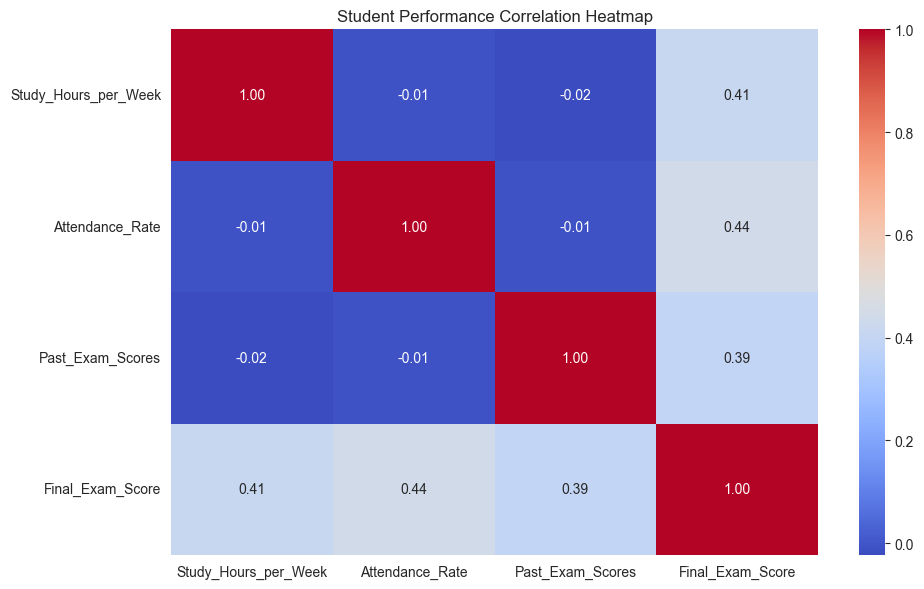

In [79]:
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(10, 6))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Student Performance Correlation Heatmap")
plt.tight_layout()
plt.savefig("correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

**Heatmap interpretation:** The predictor-to-predictor correlations are very close to zero: Study Hours vs Attendance **−0.0074**, Study Hours vs Past Exam Scores **−0.0230**, and Attendance vs Past Exam Scores **−0.0079**. Their correlations with Final Exam Score are higher but still moderate: Study Hours **0.41**, Attendance **0.44**, and Past Exam Scores **0.39**. Attendance has the strongest linear correlation with Final Exam Score among these three predictors. These are correlations, not causal relationships.

In [80]:
## Verify the passing cutoff
cutoff_analysis=df.groupby("Pass_Fail")['Final_Exam_Score'].agg(
    ['min','max','mean','count'])
print(cutoff_analysis)

           min  max       mean  count
Pass_Fail                            
Fail        50   59  53.150096   5190
Pass        60   77  65.290229   4810


## Feature selection

In [81]:
# Define the target and predictors using the original, unencoded columns.
target = 'Pass_Fail'

numeric_features = [
    'Study_Hours_per_Week',
    'Attendance_Rate',
    'Past_Exam_Scores'
]

categorical_cols = [
    'Gender',
    'Parental_Education_Level',
    'Internet_Access_at_Home',
    'Extracurricular_Activities'
]

# Exclude Final_Exam_Score (target leakage risk) and Student_ID (identifier).
X = df[numeric_features + categorical_cols].copy()
y = df[target].map({'Fail': 0, 'Pass': 1})

if y.isna().any():
    raise ValueError("Unexpected values in Pass_Fail. Check target labels.")

print("Input features shape:", X.shape)
print("Target shape:", y.shape)
display(X.head())
display(y.head())

Input features shape: (10000, 7)
Target shape: (10000,)


,Study_Hours_per_Week,Attendance_Rate,Past_Exam_Scores,Gender,Parental_Education_Level,Internet_Access_at_Home,Extracurricular_Activities
0,31.0,68.3,77.836087,Male,High School,Yes,Yes
1,16.0,78.2,73.000000,Male,PhD,No,No
2,21.0,87.5,74.000000,Female,PhD,Yes,No
3,27.0,92.1,99.000000,Female,Bachelors,No,No
4,37.0,98.7,63.000000,Female,Masters,No,Yes


0    1
1    0
2    0
3    1
4    1
Name: Pass_Fail, dtype: int64

- Remove `Final_Exam_Score` because it could leak information about the outcome
- Remove `Student_ID` because it is only an identifier.

## Why do we split before training and preprocessing?

We split the data before fitting preprocessing steps so information from the test set cannot influence training. Imputers, encoders, and scalers must learn their parameters from training data only. The test set is kept separate to provide a fair estimate of how the final model performs on unseen students.

**Note about this notebook:** The earlier EDA section imputes missing values on the full dataset before saving the cleaned CSV. That can introduce data leakage into the modelling data. This is recorded as a future improvement; for a stricter workflow, reload the original raw CSV below and fit all imputers inside the pipeline after splitting.

In [83]:
# For modelling, reload the original raw file (not the EDA-imputed cleaned file).
raw_df = pd.read_csv("Dataset/student_performance_data.csv")

target = "Pass_Fail"
numeric_features = [
    "Study_Hours_per_Week",
    "Attendance_Rate",
    "Past_Exam_Scores"
]
categorical_features = [
    "Gender",
    "Parental_Education_Level",
    "Internet_Access_at_Home",
    "Extracurricular_Activities"
]

X = raw_df[numeric_features + categorical_features].copy()
y = raw_df[target].map({"Fail": 0, "Pass": 1})

if y.isna().any():
    raise ValueError("Pass_Fail contains unexpected or missing labels.")

print("Numeric predictors:", numeric_features)
print("Categorical predictors:", categorical_features)
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Target distribution:")
print(y.map({0: "Fail", 1: "Pass"}).value_counts())

Numeric predictors: ['Study_Hours_per_Week', 'Attendance_Rate', 'Past_Exam_Scores']
Categorical predictors: ['Gender', 'Parental_Education_Level', 'Internet_Access_at_Home', 'Extracurricular_Activities']
X shape: (10000, 7)
y shape: (10000,)
Target distribution:
Pass_Fail
Fail    5190
Pass    4810
Name: count, dtype: int64


## Train-test split

We reserve 20% of the data as a final test set. `stratify=y` keeps the Pass/Fail proportions approximately the same in both subsets. The test set is not used for fitting preprocessing, cross-validation, or model selection.

In [84]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=0,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("\nTraining target proportions:")
print(y_train.value_counts(normalize=True).sort_index())
print("\nTesting target proportions:")
print(y_test.value_counts(normalize=True).sort_index())

X_train: (8000, 7)
X_test: (2000, 7)

Training target proportions:
Pass_Fail
0    0.519
1    0.481
Name: proportion, dtype: float64

Testing target proportions:
Pass_Fail
0    0.519
1    0.481
Name: proportion, dtype: float64


In [85]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_preprocessor, numeric_features),
        ("categorical", categorical_preprocessor, categorical_features)
    ],
    remainder="drop"
)

print("Preprocessing pipeline is ready.")

Preprocessing pipeline is ready.


In [86]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

dummy_model = DummyClassifier(strategy="most_frequent")
dummy_model.fit(X_train, y_train)
dummy_pred = dummy_model.predict(X_test)

baseline_accuracy = accuracy_score(y_test, dummy_pred)
print(f"Majority-class baseline accuracy: {baseline_accuracy:.4f} ({baseline_accuracy * 100:.2f}%)")

Majority-class baseline accuracy: 0.5190 (51.90%)


- I split the dataset into 80% training data and 20% testing data. I used random_state=0 to make split reproducible. I used `stratify=y` to maintain approximately the same Pass/Fail proportion in both datasets. This ensures that both sets represent the original class distribution

## Baseline model

A majority-class DummyClassifier gives a simple reference score. A trained model should be evaluated against this baseline.

- We created DummyClassifier because it acts as a baseline model. It gives us a simple benchmark to judge whether our actual machine-learning models are learning useful patterns

In [87]:
print("y_train labels:", y_train.unique())
print("y_test labels:", y_test.unique())

y_train labels: [1 0]
y_test labels: [1 0]


In [88]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Initialize the model
lr_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(max_iter=1000))
])

# Train the model
lr_pipeline.fit(X_train, y_train)

# Make predictions
lr_pred = lr_pipeline.predict(X_test)

# Evaluate the model
print("Logistic Regression Accuracy:",
      round(accuracy_score(y_test, lr_pred) * 100, 2), "%")

print("Confusion Matrix:")
print(confusion_matrix(y_test, lr_pred, labels=[0, 1]))

print("\nClassification Report:")
print(classification_report(
    y_test,
    lr_pred,
    labels=[0, 1],
    target_names=['Fail', 'Pass']
))

Logistic Regression Accuracy: 77.45 %
Confusion Matrix:
[[794 244]
 [207 755]]

Classification Report:
              precision    recall  f1-score   support

        Fail       0.79      0.76      0.78      1038
        Pass       0.76      0.78      0.77       962

    accuracy                           0.77      2000
   macro avg       0.77      0.77      0.77      2000
weighted avg       0.78      0.77      0.77      2000



### Logistic Regression – Model Evaluation

The Logistic Regression model achieved an accuracy of **77.45%** on the test dataset.

The confusion matrix shows that the model correctly classified 794 students as Fail and 755 students as Pass. However, it incorrectly classified 244 students who actually failed as Pass and 207 students who actually passed as Fail.

The classification report indicates that the model achieved an F1-score of 0.78 for the Fail class and 0.77 for the Pass class.

**Observations:**
- The model achieved 77.45% accuracy.
- The precision for the Fail class was 79%, while for the Pass class it was 76%.
- The model achieved a recall of 76% for Fail and 78% for Pass.
- It produced 451 incorrect predictions.
- Overall, the model showed reasonably balanced performance in predicting student outcomes.

**Conclusion:**

Logistic Regression provided a reasonable baseline for evaluating student performance using the selected features. It was able to identify both passing and failing students with similar performance. Other machine learning models will be evaluated to determine whether predictive accuracy can be improved.

### Decision Tree

In [89]:
from sklearn.tree import DecisionTreeClassifier

#Intialize model
dt_pipeline=Pipeline([
    ('preprocessor',preprocessor),
    ('model',DecisionTreeClassifier(random_state=0))
])

## Train model
dt_pipeline.fit(X_train,y_train)

#Predictions
dt_pred=dt_pipeline.predict(X_test)

## Accuracy
print("Decision Tree accuracy:",
      round(accuracy_score(y_test,dt_pred)*100,2),'%')

## Confusion matrix
print("\nConfusion Matrix")
print(confusion_matrix(y_test,dt_pred,labels=[0,1]))


## Classification report
print("\nClassification Report")
print(classification_report(y_test,dt_pred))

Decision Tree accuracy: 80.45 %

Confusion Matrix
[[832 206]
 [185 777]]

Classification Report
              precision    recall  f1-score   support

           0       0.82      0.80      0.81      1038
           1       0.79      0.81      0.80       962

    accuracy                           0.80      2000
   macro avg       0.80      0.80      0.80      2000
weighted avg       0.80      0.80      0.80      2000



### Decision Tree Classifier – Model Evaluation

The Decision Tree Classifier achieved an accuracy of **80.45%** on the test dataset.

The confusion matrix shows that the model correctly classified 832 students as Fail and 777 students as Pass. However, it incorrectly classified 206 students who actually failed as Pass and 185 students who actually passed as Fail.

The classification report indicates that the model achieved an F1-score of 0.81 for the Fail class and 0.80 for the Pass class.

**Observations:**
- The model achieved 80.45% accuracy.
- It performed slightly better in identifying students who failed than students who passed, based on precision and F1-score.
- It produced 391 incorrect predictions.
- Overall, the Decision Tree performed reasonably well in predicting student performance.

**Conclusion:**

The Decision Tree Classifier performed better than Logistic Regression in this experiment. Its accuracy increased from 77.45% to 80.45%, representing an improvement of 3 percentage points. Further models will be evaluated to identify whether predictive performance can be improved.


### Random Forest Classifier

Random Forest is an ensemble learning algorithm that combines multiple Decision Trees to improve prediction performance. Each tree makes its own prediction, and the final output is determined through majority voting for classification tasks.

In this project, Random Forest is used to predict whether students will Pass or Fail based on their study habits, attendance, previous exam scores, and other selected features.

**Why Random Forest?**
- Combines multiple Decision Trees.
- Can capture complex relationships between features.
- Reduces the risk of overfitting compared with a single Decision Tree.
- Can provide feature importance to identify influential predictors.

In [90]:
from sklearn.ensemble import RandomForestClassifier

## Initialize the model
rf_pipeline=Pipeline([
    ('preprocessor',preprocessor),
    ('model',RandomForestClassifier(
        n_estimators=100,
        random_state=0
    ))
])

## Train the model
rf_pipeline.fit(X_train,y_train)

##Make predictions
rf_pred=rf_pipeline.predict(X_test)

#Evaluate accuracy
print("Random Forest Accuracy:",
      round(accuracy_score(y_test,rf_pred)*100,2),"%")

## Confusion matrix
print("\nConfusion Matrix")
print(confusion_matrix(y_test,rf_pred,labels=[0,1]))

## Classification report
print("\n Classification Report")
print(classification_report(y_test,rf_pred))

Random Forest Accuracy: 87.95 %

Confusion Matrix
[[900 138]
 [103 859]]

 Classification Report
              precision    recall  f1-score   support

           0       0.90      0.87      0.88      1038
           1       0.86      0.89      0.88       962

    accuracy                           0.88      2000
   macro avg       0.88      0.88      0.88      2000
weighted avg       0.88      0.88      0.88      2000



### Random Forest – Model Evaluation

The Random Forest Classifier achieved an accuracy of **87.95%** on the test dataset.

The confusion matrix shows that the model correctly classified 900 students as Fail and 859 students as Pass. However, it incorrectly classified 138 students who actually failed as Pass and 103 students who actually passed as Fail.

The classification report indicates that the model achieved an F1-score of 0.88 for both the Fail and Pass classes.

**Observations:**
- The model achieved 87.95% accuracy.
- Precision was 90% for Fail and 86% for Pass.
- Recall was 87% for Fail and 89% for Pass.
- The model produced 241 incorrect predictions.
- It demonstrated balanced performance across both classes.

Random Forest outperformed Logistic Regression by 10.50 percentage points and Decision Tree by 7.50 percentage points.

**Conclusion:**

In the initial test-set results recorded in this notebook, Random Forest achieved the highest accuracy. The cross-validation section below provides a training-only model-selection check. Its ability to combine multiple Decision Trees helped it capture patterns in the student dataset and improve classification performance. Therefore, Random Forest is currently the best-performing model in this experiment.

### K-Nearest Neighbors (KNN) Classifier

K-Nearest Neighbors (KNN) is a supervised machine-learning algorithm used for classification and regression tasks. It predicts the class of a data point by identifying its K nearest neighbors and assigning the majority class among them.

In this project, KNN is used to predict whether students will Pass or Fail based on their selected academic and personal features.

**Why KNN?**
- Simple and easy-to-understand classification algorithm.
- Uses similarities between data points to make predictions.
- Can identify local patterns in the dataset.
- Feature scaling is important because KNN uses distance calculations.

In [91]:
from sklearn.neighbors import KNeighborsClassifier

#intialize the model
knn_pipeline=Pipeline([
    ('preprocessor',preprocessor),
    ('model',KNeighborsClassifier(n_neighbors=5))
])

## Train the model
knn_pipeline.fit(X_train,y_train)

## Make predictions
knn_pred=knn_pipeline.predict(X_test)

## Evaluate the accuracy
print("KNN Accuracy:",
      round(accuracy_score(y_test,knn_pred)*100,2),"%")

## Confusion matrix
print("\nConfusion matrix")
print(confusion_matrix(y_test,knn_pred,labels=[0,1]))

## Classification report
print("\nClassification Report")
print(classification_report(y_test,knn_pred))

KNN Accuracy: 87.15 %

Confusion matrix
[[887 151]
 [106 856]]

Classification Report
              precision    recall  f1-score   support

           0       0.89      0.85      0.87      1038
           1       0.85      0.89      0.87       962

    accuracy                           0.87      2000
   macro avg       0.87      0.87      0.87      2000
weighted avg       0.87      0.87      0.87      2000



### KNN Model Evaluation

The K-Nearest Neighbors (KNN) model achieved an accuracy of **87.15%** on the test dataset.

The confusion matrix shows that the model correctly classified 887 students as Fail and 856 students as Pass. It incorrectly classified 151 Fail students as Pass and 106 Pass students as Fail.

The classification report shows an F1-score of 0.87 for both classes. The model achieved a recall of 0.85 for Fail students and 0.89 for Pass students, indicating reasonably balanced performance.

Overall, KNN performed well, achieving higher accuracy than Logistic Regression and Decision Tree. However, its accuracy was slightly lower than Random Forest. Therefore, Random Forest remains the best-performing model among the four models evaluated so far.

### Support Vector Machine (SVM) Model

Support Vector Machine (SVM) is a supervised machine learning algorithm used for classification. It finds an optimal decision boundary that separates different classes.

In this project, SVM is used to classify students into two categories: Fail (0) and Pass (1).

The model uses the RBF kernel, which can identify nonlinear relationships between features. The preprocessing pipeline handles missing values, encodes categorical variables, and scales numerical features before training.

In [92]:
from sklearn.svm import SVC

## Create SVM pipeline
svm_pipeline=Pipeline([
    ('preprocessor',preprocessor),
    ('model',SVC(kernel='rbf',C=1.0,random_state=0))
])

## Train the model
svm_pipeline.fit(X_train,y_train)

## Make predictions
svm_pred=svm_pipeline.predict(X_test)
print("SVM Accuracy:",
      round(accuracy_score(y_test,svm_pred)*100,2),"%")

## Confusion matrix
print("\nConfusion matrix:")
print(confusion_matrix(y_test,svm_pred,labels=[0,1]))

## Classification report
print("\nClassification report")
print(classification_report(
    y_test,svm_pred,labels=[0,1],target_names=["Fail","Pass"]
))


SVM Accuracy: 85.15 %

Confusion matrix:
[[836 202]
 [ 95 867]]

Classification report
              precision    recall  f1-score   support

        Fail       0.90      0.81      0.85      1038
        Pass       0.81      0.90      0.85       962

    accuracy                           0.85      2000
   macro avg       0.85      0.85      0.85      2000
weighted avg       0.86      0.85      0.85      2000



### SVM – Model Evaluation

The Support Vector Machine (SVM) model achieved an accuracy of **85.15%** on the test dataset.

The confusion matrix shows that it correctly classified 836 students as Fail and 867 students as Pass. It incorrectly classified 202 Fail students as Pass and 95 Pass students as Fail.

**Observations:**
- The model achieved 85.15% test accuracy.
- Fail-class precision was 0.90 and recall was 0.81.
- Pass-class precision was 0.81 and recall was 0.90.
- The model identified Pass students with higher recall, while its Fail-class precision was higher.
- Its accuracy was lower than the initial Random Forest and KNN results, but higher than Logistic Regression, Decision Tree, Gaussian Naive Bayes, and Gradient Boosting.

**Conclusion:**

The RBF-kernel SVM performed well and showed a difference in precision and recall between the two classes. The preferred model should also be checked using cross-validation on the training data before the final test evaluation.


### Gaussian Naive Bayes Model

Gaussian Naive Bayes is a supervised machine learning algorithm used for classification. It applies Bayes' theorem and assumes that features are conditionally independent given the target class.

Gaussian Naive Bayes assumes that numerical features follow a Gaussian (normal) distribution.

In this project, the model is used to classify students into two categories: Fail (0) and Pass (1).

The preprocessing pipeline handles missing values, encodes categorical variables, and scales numerical features before training the model.

In [93]:
from sklearn.naive_bayes import GaussianNB

## Create Gaussian Naive Bayes pipeline
nb_pipeline=Pipeline([
    ("preprocessor",preprocessor),
    ("model",GaussianNB())
])

## Train the model
nb_pipeline.fit(X_train,y_train)

# Make predictions
nb_pred=nb_pipeline.predict(X_test)

## Make predictions
print("Naive Bayes accuracy",
      round(accuracy_score(y_test,nb_pred)*100,2),"%")

## Confusion matrix
print("\nConfusion matrix")
print(confusion_matrix(y_test,nb_pred,labels=[0,1]))

## Classification report
print("\nClassification Report")
print(classification_report(
    y_test,nb_pred,labels=[0,1],target_names=['Fail','Pass']
))

Naive Bayes accuracy 76.8 %

Confusion matrix
[[799 239]
 [225 737]]

Classification Report
              precision    recall  f1-score   support

        Fail       0.78      0.77      0.77      1038
        Pass       0.76      0.77      0.76       962

    accuracy                           0.77      2000
   macro avg       0.77      0.77      0.77      2000
weighted avg       0.77      0.77      0.77      2000



### Naive Bayes Model Evaluation

The Gaussian Naive Bayes model achieved an accuracy of **76.80%** on the test dataset.

The confusion matrix shows that the model correctly classified 799 students as Fail and 737 students as Pass. It incorrectly classified 239 Fail students as Pass and 225 Pass students as Fail.

The classification report shows an F1-score of 0.77 for Fail students and 0.76 for Pass students. Both classes have a recall of 0.77, indicating that the model performs similarly when identifying Fail and Pass students.

Overall, Gaussian Naive Bayes provides balanced classification performance, but its accuracy is lower than the other models evaluated so far.

### Gradient Boosting Classifier

Gradient Boosting is a supervised machine learning algorithm used for classification and regression tasks.

It builds multiple decision trees sequentially. Each new tree focuses on correcting the errors made by the previous trees.

In this project, Gradient Boosting is used to classify students into two categories: Fail (0) and Pass (1).

The preprocessing pipeline handles missing values, encodes categorical variables, and scales numerical features before training the model.

In [94]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline

# Create Gradient Boosting pipeline
gb_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        random_state=0
    ))
])

# Train the model
gb_pipeline.fit(X_train, y_train)

# Make predictions
gb_pred = gb_pipeline.predict(X_test)

print("Gradient Boosting Accuracy:",
      round(accuracy_score(y_test, gb_pred) * 100, 2), "%")

## Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, gb_pred, labels=[0, 1]))

## Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    gb_pred,
    labels=[0, 1],
    target_names=['Fail', 'Pass']
))

Gradient Boosting Accuracy: 81.65 %

Confusion Matrix:
[[816 222]
 [145 817]]

Classification Report:
              precision    recall  f1-score   support

        Fail       0.85      0.79      0.82      1038
        Pass       0.79      0.85      0.82       962

    accuracy                           0.82      2000
   macro avg       0.82      0.82      0.82      2000
weighted avg       0.82      0.82      0.82      2000



### Gradient Boosting – Model Evaluation

The Gradient Boosting Classifier achieved an accuracy of **81.65%** on the test dataset.

The confusion matrix shows that it correctly classified 816 students as Fail and 817 students as Pass. It incorrectly classified 222 Fail students as Pass and 145 Pass students as Fail.

**Observations:**
- The model achieved 81.65% test accuracy.
- Fail-class precision was 0.85 and recall was 0.79.
- Pass-class precision was 0.79 and recall was 0.85.
- The model identified Pass students with higher recall, while Fail-class precision was higher.
- Its initial test accuracy was higher than Logistic Regression and Gaussian Naive Bayes, but lower than Random Forest, KNN, SVM, and Decision Tree.

**Conclusion:**

Gradient Boosting provided a useful ensemble-learning comparison. Its sequential trees achieved moderate performance on this test split. Cross-validation will help assess whether the observed performance is consistent across training folds.

## Comparison of Classification Models

Seven machine learning classification algorithms were implemented and evaluated using the same training and testing datasets.

The accuracy score of each model was used to compare their classification performance and identify the best-performing model.

In [95]:
# Build the comparison from the predictions created by each model.
# This avoids manually typing accuracy values into the table.

from sklearn.metrics import accuracy_score
import pandas as pd

model_predictions = {
    "Logistic Regression": lr_pred,
    "Decision Tree": dt_pred,
    "Random Forest": rf_pred,
    "KNN": knn_pred,
    "SVM": svm_pred,
    "Gaussian Naive Bayes": nb_pred,
    "Gradient Boosting": gb_pred
}

comparison_rows = [{
    "Model": "Dummy baseline",
    "Accuracy (%)": accuracy_score(y_test, dummy_pred) * 100
}]

for model_name, predictions in model_predictions.items():
    comparison_rows.append({
        "Model": model_name,
        "Accuracy (%)": accuracy_score(y_test, predictions) * 100
    })

results_df = pd.DataFrame(comparison_rows)
results_df = results_df.sort_values(
    by="Accuracy (%)",
    ascending=False
).reset_index(drop=True)

results_df["Accuracy (%)"] = results_df["Accuracy (%)"].round(2)
display(results_df)


,Model,Accuracy (%)
0,Random Forest,87.95
1,KNN,87.15
2,SVM,85.15
3,Gradient Boosting,81.65
4,Decision Tree,80.45
5,Logistic Regression,77.45
6,Gaussian Naive Bayes,76.80
7,Dummy baseline,51.90


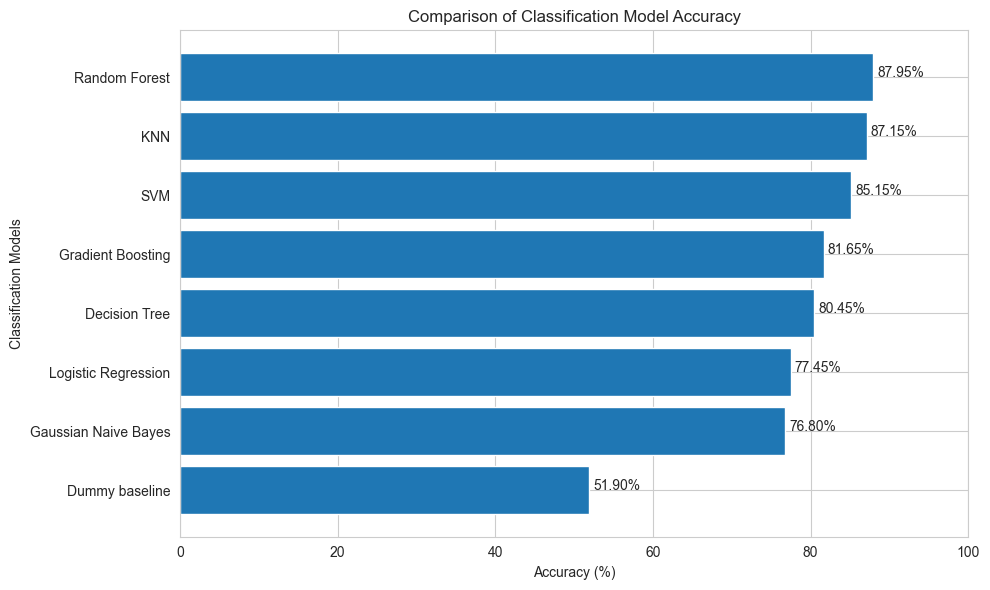

Chart saved as classification_model_comparison.png


In [96]:
# Plot and save the model comparison chart.
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.barh(results_df["Model"], results_df["Accuracy (%)"])
plt.xlabel("Accuracy (%)")
plt.ylabel("Classification Models")
plt.title("Comparison of Classification Model Accuracy")
plt.xlim(0, 100)
plt.gca().invert_yaxis()

for index, value in enumerate(results_df["Accuracy (%)"]):
    plt.text(value + 0.5, index, f"{value:.2f}%")

plt.tight_layout()
plt.savefig(
    "classification_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("Chart saved as classification_model_comparison.png")


## Cross-validation for model selection

The earlier model accuracies were calculated on one test split. To check how consistently each algorithm performs, this section uses **5-fold stratified cross-validation on the training data only**.

The held-out test set is not used during cross-validation or model selection. Each fold fits its own preprocessing steps, because preprocessing is inside each pipeline.

The model with the highest mean cross-validation accuracy will be selected for the final test evaluation. The result may differ from the earlier single-split ranking.


In [97]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, recall_score
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from scipy import sparse
import pandas as pd
import numpy as np

# GaussianNB requires dense transformed input.
def make_dense(values):
    return values.toarray() if sparse.issparse(values) else values

cv_models = {
    "Logistic Regression": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", LogisticRegression(max_iter=1000, random_state=0))
    ]),
    "Decision Tree": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", DecisionTreeClassifier(random_state=0))
    ]),
    "Random Forest": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", RandomForestClassifier(n_estimators=100, random_state=0))
    ]),
    "KNN": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),
    "SVM": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", SVC(kernel="rbf", C=1.0, random_state=0))
    ]),
    "Gaussian Naive Bayes": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("to_dense", FunctionTransformer(make_dense, accept_sparse=True)),
        ("model", GaussianNB())
    ]),
    "Gradient Boosting": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", GradientBoostingClassifier(
            n_estimators=100,
            learning_rate=0.1,
            random_state=0
        ))
    ])
}

# Class 0 is Fail, so Fail recall measures how many actually failing students
# are correctly identified as Fail.
scoring = {
    "accuracy": "accuracy",
    "fail_recall": make_scorer(recall_score, pos_label=0),
    "macro_f1": "f1_macro"
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
cv_rows = []

for name, pipeline in cv_models.items():
    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=False,
        n_jobs=None
    )
    cv_rows.append({
        "Model": name,
        "Mean CV Accuracy (%)": scores["test_accuracy"].mean() * 100,
        "Accuracy SD (%)": scores["test_accuracy"].std() * 100,
        "Mean Fail Recall (%)": scores["test_fail_recall"].mean() * 100,
        "Fail Recall SD (%)": scores["test_fail_recall"].std() * 100,
        "Mean Macro F1 (%)": scores["test_macro_f1"].mean() * 100,
        "Macro F1 SD (%)": scores["test_macro_f1"].std() * 100
    })

cv_results = pd.DataFrame(cv_rows).sort_values(
    "Mean CV Accuracy (%)", ascending=False
).reset_index(drop=True)

numeric_cols = [c for c in cv_results.columns if c != "Model"]
cv_results[numeric_cols] = cv_results[numeric_cols].round(2)
display(cv_results)

# Compare the two close accuracy contenders using the project priority:
# 1) Fail recall, 2) macro F1, 3) accuracy as a final tie-breaker.
knn_rf = cv_results[cv_results["Model"].isin(["KNN", "Random Forest"])].copy()
if len(knn_rf) != 2:
    raise ValueError("Both KNN and Random Forest must be present in cv_results.")

knn_rf = knn_rf.sort_values(
    ["Mean Fail Recall (%)", "Mean Macro F1 (%)", "Mean CV Accuracy (%)"],
    ascending=False
).reset_index(drop=True)

best_cv_model_name = knn_rf.loc[0, "Model"]
chosen = knn_rf.iloc[0]
other = knn_rf.iloc[1]

print("\nKNN vs Random Forest (training-only 5-fold CV):")
display(knn_rf[[
    "Model", "Mean CV Accuracy (%)", "Accuracy SD (%)",
    "Mean Fail Recall (%)", "Fail Recall SD (%)", "Mean Macro F1 (%)"
]])

selection_reason = (
    f"{best_cv_model_name} was selected from KNN and Random Forest because it had "
    f"the higher mean Fail recall ({chosen['Mean Fail Recall (%)']:.2f}% versus "
    f"{other['Mean Fail Recall (%)']:.2f}%). Macro F1 was used as the next "
    f"tie-breaker, and mean CV accuracy as the final tie-breaker."
    if chosen["Mean Fail Recall (%)"] != other["Mean Fail Recall (%)"]
    else (
        f"{best_cv_model_name} was selected because KNN and Random Forest had "
        f"the same mean Fail recall; macro F1 was the next tie-breaker. "
        f"Mean CV accuracy was used only if macro F1 was also tied."
    )
)
print("\nSelection rule: prioritize Fail recall, then macro F1, then accuracy.")
print(selection_reason)
print(
    "\nTransparency note: the earlier single-split test accuracies had already "
    "been viewed before this CV-based choice. Therefore, this is not a fully "
    "blinded model-selection process; interpret the final test result cautiously."
)


,Model,Mean CV Accuracy (%),Accuracy SD (%),Mean Fail Recall (%),Fail Recall SD (%),Mean Macro F1 (%),Macro F1 SD (%)
0,KNN,86.26,0.45,85.69,1.36,86.25,0.45
1,Random Forest,85.99,0.44,86.25,1.38,85.97,0.44
2,SVM,83.61,1.14,80.44,2.49,83.61,1.14
3,Gradient Boosting,81.77,0.66,81.19,1.89,81.76,0.66
4,Decision Tree,79.20,0.80,79.79,1.24,79.17,0.80
5,Logistic Regression,77.95,1.08,78.66,1.48,77.92,1.08
6,Gaussian Naive Bayes,75.60,1.16,76.83,1.45,75.55,1.17



KNN vs Random Forest (training-only 5-fold CV):


,Model,Mean CV Accuracy (%),Accuracy SD (%),Mean Fail Recall (%),Fail Recall SD (%),Mean Macro F1 (%)
0,Random Forest,85.99,0.44,86.25,1.38,85.97
1,KNN,86.26,0.45,85.69,1.36,86.25



Selection rule: prioritize Fail recall, then macro F1, then accuracy.
Random Forest was selected from KNN and Random Forest because it had the higher mean Fail recall (86.25% versus 85.69%). Macro F1 was used as the next tie-breaker, and mean CV accuracy as the final tie-breaker.

Transparency note: the earlier single-split test accuracies had already been viewed before this CV-based choice. Therefore, this is not a fully blinded model-selection process; interpret the final test result cautiously.


## Final model training and test-set evaluation

The model selected by cross-validation is now fitted on the complete training set and evaluated once on the untouched test set.

This final test score is the main estimate of performance on unseen data. Do not keep changing model settings based on this test score; use training data and cross-validation for further tuning.


In [98]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

final_model = clone(cv_models[best_cv_model_name])
final_model.fit(X_train, y_train)

final_test_predictions = final_model.predict(X_test)
final_test_accuracy = accuracy_score(y_test, final_test_predictions)

print("Selected final model:", best_cv_model_name)
print(f"Final test accuracy: {final_test_accuracy * 100:.2f}%")
print("\nConfusion matrix (rows: actual, columns: predicted; order Fail, Pass):")
print(confusion_matrix(y_test, final_test_predictions, labels=[0, 1]))
print("\nClassification report:")
print(classification_report(
    y_test,
    final_test_predictions,
    labels=[0, 1],
    target_names=["Fail", "Pass"],
    zero_division=0
))


Selected final model: Random Forest
Final test accuracy: 87.95%

Confusion matrix (rows: actual, columns: predicted; order Fail, Pass):
[[900 138]
 [103 859]]

Classification report:
              precision    recall  f1-score   support

        Fail       0.90      0.87      0.88      1038
        Pass       0.86      0.89      0.88       962

    accuracy                           0.88      2000
   macro avg       0.88      0.88      0.88      2000
weighted avg       0.88      0.88      0.88      2000



## Decision-threshold experiment for the selected final model

The default binary-classification threshold is 0.50. Because the project prioritizes identifying students who may Fail, this experiment compares thresholds of **0.40, 0.50, and 0.60**.

A student is predicted as Pass when the predicted Pass probability is at least the threshold; otherwise the student is predicted as Fail. Raising the threshold generally makes the model more cautious about predicting Pass, which may increase Fail recall while changing overall accuracy.

This is an analysis of the already selected model. Do not choose a threshold based on the held-out test set and then report that same test set as an unbiased final evaluation. Ideally, choose the threshold using training-only validation, then evaluate it once on the test set.


In [99]:
from sklearn.metrics import accuracy_score, recall_score, f1_score
import pandas as pd
import numpy as np

final_estimator = final_model.named_steps["model"]
if not hasattr(final_estimator, "predict_proba"):
    raise TypeError(
        "The selected model does not support predict_proba. "
        "This threshold experiment requires a probability-capable model."
    )

class_labels = list(final_estimator.classes_)
pass_class_index = class_labels.index(1)
pass_probabilities = final_model.predict_proba(X_test)[:, pass_class_index]

threshold_rows = []
for threshold in [0.40, 0.50, 0.60]:
    # Predict Pass (1) if P(Pass) >= threshold; otherwise predict Fail (0).
    threshold_predictions = np.where(pass_probabilities >= threshold, 1, 0)

    threshold_rows.append({
        "Pass probability threshold": threshold,
        "Accuracy (%)": accuracy_score(y_test, threshold_predictions) * 100,
        "Fail recall (%)": recall_score(
            y_test, threshold_predictions, pos_label=0, zero_division=0
        ) * 100,
        "Macro F1 (%)": f1_score(
            y_test, threshold_predictions, average="macro", zero_division=0
        ) * 100,
        "Students predicted Fail": int((threshold_predictions == 0).sum())
    })

threshold_results = pd.DataFrame(threshold_rows)
display(threshold_results.round(2))

print(
    "Interpret the table as a trade-off: prioritize Fail recall if missing "
    "students who are at risk of failing is more costly, but also check the "
    "corresponding accuracy and number of students flagged as Fail."
)


,Pass probability threshold,Accuracy (%),Fail recall (%),Macro F1 (%),Students predicted Fail
0,0.4,87.45,81.70,87.44,909
1,0.5,88.00,86.32,88.00,994
2,0.6,87.10,89.40,87.06,1076


Interpret the table as a trade-off: prioritize Fail recall if missing students who are at risk of failing is more costly, but also check the corresponding accuracy and number of students flagged as Fail.


**Accuracy note:** The official final test accuracy is **87.95%**, calculated from `final_model.predict(X_test)`. The threshold table's 0.50 row may show **88.00%** because the custom rule uses `P(Pass) >= 0.50`, assigning exact 0.50 ties to Pass. The estimator's built-in `predict()` tie handling can assign those cases differently. Use **87.95%** as the official final-model score and retain the threshold-table value only as part of the threshold experiment.


## Feature importance using permutation importance

Permutation importance measures how much the selected model's score decreases when one input feature is shuffled. A larger positive decrease indicates that the model relied more on that feature for its predictions.

This analysis uses the final selected model and the held-out test data. Treat the result as an interpretation of this fitted model, not proof that a feature causes students to pass or fail.


In [100]:
from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

# Compare permutation importance for both close contenders using the same held-out
# test rows. This is for interpretation only, not for choosing the model.
knn_for_importance = clone(cv_models["KNN"]).fit(X_train, y_train)
rf_for_importance = clone(cv_models["Random Forest"]).fit(X_train, y_train)

def get_permutation_importance(fitted_pipeline, model_label):
    result = permutation_importance(
        fitted_pipeline,
        X_test,
        y_test,
        scoring="accuracy",
        n_repeats=10,
        random_state=0,
        n_jobs=None
    )
    return pd.DataFrame({
        "Feature": X_test.columns,
        f"{model_label} Mean Importance": result.importances_mean,
        f"{model_label} SD": result.importances_std
    })

knn_importance_df = get_permutation_importance(knn_for_importance, "KNN")
rf_importance_df = get_permutation_importance(rf_for_importance, "Random Forest")

feature_importance_comparison_df = knn_importance_df.merge(
    rf_importance_df, on="Feature"
)
feature_importance_comparison_df["KNN Rank"] = (
    feature_importance_comparison_df["KNN Mean Importance"]
    .rank(ascending=False, method="min").astype(int)
)
feature_importance_comparison_df["Random Forest Rank"] = (
    feature_importance_comparison_df["Random Forest Mean Importance"]
    .rank(ascending=False, method="min").astype(int)
)
feature_importance_comparison_df = feature_importance_comparison_df.sort_values(
    "Random Forest Rank"
).reset_index(drop=True)

display(feature_importance_comparison_df.round(4))

# Show both rankings side by side.
knn_ranked = feature_importance_comparison_df.sort_values("KNN Rank")
rf_ranked = feature_importance_comparison_df.sort_values("Random Forest Rank")
print("KNN feature ranking:")
display(knn_ranked[["KNN Rank", "Feature", "KNN Mean Importance"]].round(4))
print("Random Forest feature ranking:")
display(rf_ranked[["Random Forest Rank", "Feature", "Random Forest Mean Importance"]].round(4))

numeric_set = set(numeric_features)
knn_numeric_top3 = set(knn_ranked.head(3)["Feature"]) & numeric_set
rf_numeric_top3 = set(rf_ranked.head(3)["Feature"]) & numeric_set

if len(knn_numeric_top3) == 3 and len(rf_numeric_top3) == 3:
    importance_interpretation = (
        "All three numerical predictors appear in the top three for both models. "
        "This agreement makes the numerical-feature pattern more consistent across "
        "these two algorithms, although permutation importance is not causal evidence."
    )
elif len(knn_numeric_top3) >= 2 and len(rf_numeric_top3) >= 2:
    importance_interpretation = (
        "Most of the numerical predictors appear near the top in both models. "
        "This provides some cross-model agreement, but the rankings are not identical."
    )
else:
    importance_interpretation = (
        "The numerical predictors do not dominate the top three in both models. "
        "The rankings differ by algorithm, so do not claim that numerical features "
        "are consistently the most important."
    )

print("\nInterpretation:", importance_interpretation)
print(
    "Caution: KNN uses distances, and one-hot encoded categorical columns can "
    "strongly affect those distances. Its permutation importance may therefore "
    "make categorical predictors appear especially influential. Compare the "
    "KNN and Random Forest rankings rather than treating KNN rankings alone as "
    "a definitive measure."
)

# Retain a selected-model importance table for the final observations section.
selected_importance_column = (
    "KNN Mean Importance" if best_cv_model_name == "KNN"
    else "Random Forest Mean Importance"
)
feature_importance_df = feature_importance_comparison_df[
    ["Feature", selected_importance_column]
].rename(columns={selected_importance_column: "Mean Importance"}).sort_values(
    "Mean Importance", ascending=False
).reset_index(drop=True)


,Feature,KNN Mean Importance,KNN SD,Random Forest Mean Importance,Random Forest SD,KNN Rank,Random Forest Rank
0,Study_Hours_per_Week,0.1490,0.0078,0.1603,0.0074,3,1
1,Attendance_Rate,0.1530,0.0060,0.1569,0.0070,2,2
2,Past_Exam_Scores,0.1558,0.0093,0.1566,0.0092,1,3
3,Parental_Education_Level,0.1310,0.0049,0.1050,0.0064,4,4
4,Extracurricular_Activities,0.0809,0.0066,0.0594,0.0051,5,5
5,Gender,0.0609,0.0034,0.0504,0.0044,7,6
6,Internet_Access_at_Home,0.0753,0.0061,0.0463,0.0043,6,7


KNN feature ranking:


,KNN Rank,Feature,KNN Mean Importance
2,1,Past_Exam_Scores,0.1558
1,2,Attendance_Rate,0.1530
0,3,Study_Hours_per_Week,0.1490
3,4,Parental_Education_Level,0.1310
4,5,Extracurricular_Activities,0.0809
6,6,Internet_Access_at_Home,0.0753
5,7,Gender,0.0609


Random Forest feature ranking:


,Random Forest Rank,Feature,Random Forest Mean Importance
0,1,Study_Hours_per_Week,0.1603
1,2,Attendance_Rate,0.1569
2,3,Past_Exam_Scores,0.1566
3,4,Parental_Education_Level,0.1050
4,5,Extracurricular_Activities,0.0594
5,6,Gender,0.0504
6,7,Internet_Access_at_Home,0.0463



Interpretation: All three numerical predictors appear in the top three for both models. This agreement makes the numerical-feature pattern more consistent across these two algorithms, although permutation importance is not causal evidence.
Caution: KNN uses distances, and one-hot encoded categorical columns can strongly affect those distances. Its permutation importance may therefore make categorical predictors appear especially influential. Compare the KNN and Random Forest rankings rather than treating KNN rankings alone as a definitive measure.


## Logistic Regression coefficients

Logistic Regression coefficients show the direction and size of each encoded feature's contribution to the model's decision score.

- A positive coefficient moves the prediction score toward **Pass (1)**.
- A negative coefficient moves the prediction score toward **Fail (0)**.
- The magnitude depends on the feature encoding and scaling, so compare coefficients carefully.
- These are associations learned by the model, not causal effects.


,Feature,Coefficient,Absolute Coefficient
0,numeric__Attendance_Rate,1.2707,1.2707
1,numeric__Past_Exam_Scores,1.2049,1.2049
2,numeric__Study_Hours_per_Week,1.1730,1.1730
3,categorical__Extracurricular_Activities_Yes,0.2263,0.2263
4,categorical__Extracurricular_Activities_No,-0.2262,0.2262
5,categorical__Parental_Education_Level_PhD,-0.1651,0.1651
6,categorical__Internet_Access_at_Home_No,0.1574,0.1574
7,categorical__Internet_Access_at_Home_Yes,-0.1573,0.1573
8,categorical__Parental_Education_Level_Masters,0.1388,0.1388
9,categorical__Gender_Female,0.1062,0.1062


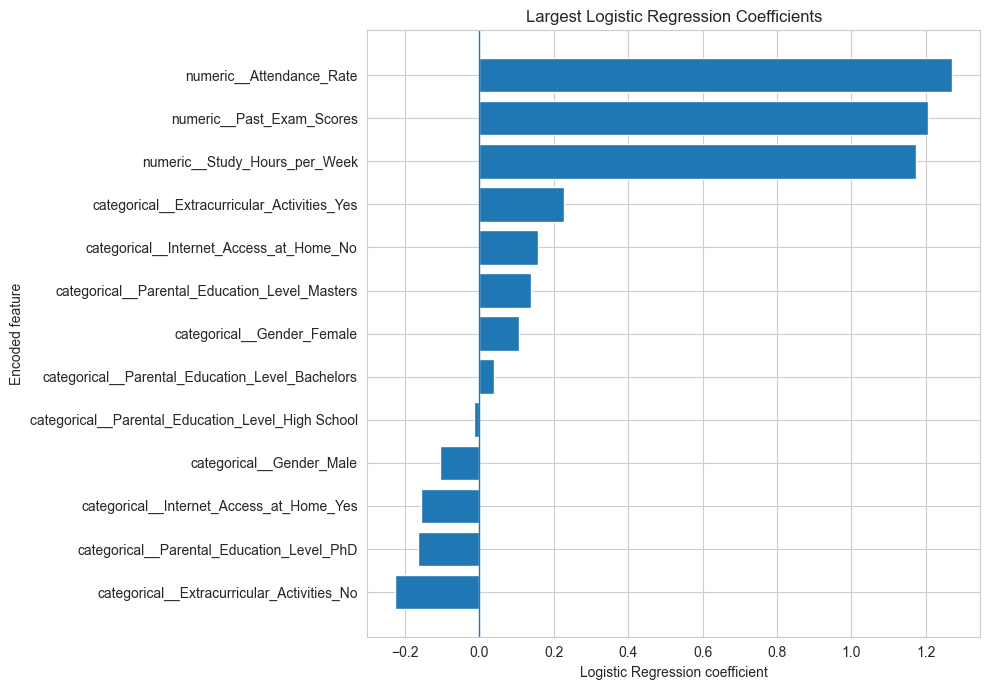

Logistic Regression coefficient chart saved.


In [101]:
# lr_pipeline was fitted earlier in the Logistic Regression section.
# Retrieve the transformed feature names and their corresponding coefficients.

lr_estimator = lr_pipeline.named_steps["model"]
lr_feature_names = lr_pipeline.named_steps["preprocessor"].get_feature_names_out()
lr_coefficients = lr_estimator.coef_[0]

lr_coefficients_df = pd.DataFrame({
    "Feature": lr_feature_names,
    "Coefficient": lr_coefficients
})
lr_coefficients_df["Absolute Coefficient"] = (
    lr_coefficients_df["Coefficient"].abs()
)
lr_coefficients_df = lr_coefficients_df.sort_values(
    "Absolute Coefficient",
    ascending=False
).reset_index(drop=True)

display(lr_coefficients_df.round(4))

# Plot the 15 coefficients with the largest absolute values.
top_lr = lr_coefficients_df.head(15).sort_values("Coefficient")

plt.figure(figsize=(10, 7))
plt.barh(top_lr["Feature"], top_lr["Coefficient"])
plt.axvline(0, linewidth=1)
plt.xlabel("Logistic Regression coefficient")
plt.ylabel("Encoded feature")
plt.title("Largest Logistic Regression Coefficients")
plt.tight_layout()
plt.savefig(
    "logistic_regression_coefficients.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("Logistic Regression coefficient chart saved.")


### Important note on duplicated one-hot coefficients

The `OneHotEncoder` uses `drop=None`, so a binary categorical feature is represented by both category columns. For example, `Extracurricular_Activities_Yes` and `Extracurricular_Activities_No` can have coefficients that are approximately equal and opposite (such as +0.2263 and -0.2262).

**Interpret the two coefficients as one categorical contrast, not as two independent findings.** They describe the same Yes-versus-No distinction from opposite sides. Do not count both as separate evidence that two different factors affect the outcome.


## Final observations – generated from the notebook results

Run the code cell below after running all previous sections. It builds a project-ready summary from the actual values calculated in this notebook, rather than inserting guessed numbers.


In [102]:
from IPython.display import display, Markdown

# Use the measured values generated by the notebook.
baseline_pct = baseline_accuracy * 100
selected_test_pct = final_test_accuracy * 100

top_features = feature_importance_df.head(3)["Feature"].tolist()
top_features_text = ", ".join(top_features) if top_features else "No feature-importance results available"

# Treat the Yes/No one-hot pair as one categorical contrast.
yes_rows = lr_coefficients_df[
    lr_coefficients_df["Feature"].str.endswith("Extracurricular_Activities_Yes")
]
no_rows = lr_coefficients_df[
    lr_coefficients_df["Feature"].str.endswith("Extracurricular_Activities_No")
]
if len(yes_rows) and len(no_rows):
    extracurricular_contrast = (
        float(yes_rows.iloc[0]["Coefficient"]) -
        float(no_rows.iloc[0]["Coefficient"])
    )
    extracurricular_contrast_text = (
        f"Extracurricular Activities (Yes vs No): "
        f"+{extracurricular_contrast:.4f} log-odds contrast"
    )
else:
    extracurricular_contrast_text = (
        "Extracurricular Activities Yes/No contrast unavailable"
    )

# Report the non-duplicate parental-education coefficient noted in the analysis.
phd_rows = lr_coefficients_df[
    lr_coefficients_df["Feature"].str.endswith("Parental_Education_Level_PhD")
]
if len(phd_rows):
    strongest_negative = (
        f"Parental_Education_Level_PhD "
        f"({float(phd_rows.iloc[0]['Coefficient']):.4f})"
    )
else:
    # Fallback excludes the binary extracurricular Yes/No mirror pair.
    non_mirror = lr_coefficients_df[
        ~lr_coefficients_df["Feature"].str.endswith(
            ("Extracurricular_Activities_Yes", "Extracurricular_Activities_No")
        )
    ]
    negative_rows = non_mirror[non_mirror["Coefficient"] < 0].sort_values(
        "Coefficient"
    )
    strongest_negative = (
        f"{negative_rows.iloc[0]['Feature']} "
        f"({negative_rows.iloc[0]['Coefficient']:.4f})"
        if len(negative_rows) else "No negative non-duplicate coefficient"
    )

positive_rows = lr_coefficients_df[
    (lr_coefficients_df["Coefficient"] > 0) &
    (~lr_coefficients_df["Feature"].str.endswith(
        ("Extracurricular_Activities_Yes", "Extracurricular_Activities_No")
    ))
].sort_values("Coefficient", ascending=False)
strongest_positive = (
    f"{positive_rows.iloc[0]['Feature']} "
    f"({positive_rows.iloc[0]['Coefficient']:.4f})"
    if len(positive_rows) else "No positive non-duplicate coefficient"
)

knn_cv_row = cv_results[cv_results["Model"] == "KNN"].iloc[0]
rf_cv_row = cv_results[cv_results["Model"] == "Random Forest"].iloc[0]

summary = f"""
### Final observations

The majority-class Dummy Classifier achieved **{baseline_pct:.2f}%** accuracy on the held-out test split. Among the two close contenders, **{best_cv_model_name}** was selected using 5-fold cross-validation on the training data. The decision prioritized mean Fail recall, followed by macro F1, and used mean accuracy only as a final tie-breaker.

KNN's cross-validation results were: mean accuracy **{knn_cv_row['Mean CV Accuracy (%)']:.2f}%**, mean Fail recall **{knn_cv_row['Mean Fail Recall (%)']:.2f}%**, and mean macro F1 **{knn_cv_row['Mean Macro F1 (%)']:.2f}%**. Random Forest's results were: mean accuracy **{rf_cv_row['Mean CV Accuracy (%)']:.2f}%**, mean Fail recall **{rf_cv_row['Mean Fail Recall (%)']:.2f}%**, and mean macro F1 **{rf_cv_row['Mean Macro F1 (%)']:.2f}%**.

The selected model achieved **{selected_test_pct:.2f}%** accuracy on the held-out test split. The official final score is calculated from `final_model.predict(X_test)`; the 0.50 probability-threshold row can differ slightly because it assigns exact 0.50 ties to Pass (`>= 0.50`), while the estimator's default prediction rule may resolve ties differently. The top three features in the selected model's permutation-importance ranking were **{top_features_text}**. The strongest positive non-duplicate Logistic Regression coefficient was **{strongest_positive}**. The binary extracurricular coefficient pair is reported as one contrast: **{extracurricular_contrast_text}**. The strongest negative non-duplicate coefficient was **{strongest_negative}**.

The Logistic Regression coefficients for the two levels of a binary one-hot encoded category must be interpreted as one contrast, not two independent findings. Also, the earlier test-set scores had already been inspected before this cross-validation-based choice, so the selection process was not fully blinded and the final test result should be interpreted cautiously.
"""
display(Markdown(summary))



### Final observations

The majority-class Dummy Classifier achieved **51.90%** accuracy on the held-out test split. Among the two close contenders, **Random Forest** was selected using 5-fold cross-validation on the training data. The decision prioritized mean Fail recall, followed by macro F1, and used mean accuracy only as a final tie-breaker.

KNN's cross-validation results were: mean accuracy **86.26%**, mean Fail recall **85.69%**, and mean macro F1 **86.25%**. Random Forest's results were: mean accuracy **85.99%**, mean Fail recall **86.25%**, and mean macro F1 **85.97%**.

The selected model achieved **87.95%** accuracy on the held-out test split. The official final score is calculated from `final_model.predict(X_test)`; the 0.50 probability-threshold row can differ slightly because it assigns exact 0.50 ties to Pass (`>= 0.50`), while the estimator's default prediction rule may resolve ties differently. The top three features in the selected model's permutation-importance ranking were **Study_Hours_per_Week, Attendance_Rate, Past_Exam_Scores**. The strongest positive non-duplicate Logistic Regression coefficient was **numeric__Attendance_Rate (1.2707)**. The binary extracurricular coefficient pair is reported as one contrast: **Extracurricular Activities (Yes vs No): +0.4524 log-odds contrast**. The strongest negative non-duplicate coefficient was **Parental_Education_Level_PhD (-0.1651)**.

The Logistic Regression coefficients for the two levels of a binary one-hot encoded category must be interpreted as one contrast, not two independent findings. Also, the earlier test-set scores had already been inspected before this cross-validation-based choice, so the selection process was not fully blinded and the final test result should be interpreted cautiously.


## Limitations of the study

1. **Single dataset:** The analysis uses one student dataset and one train-test split. The results may not generalize to students from other schools, regions, or academic years.
2. **Moderate correlations:** Some predictors may be correlated with one another. This can affect coefficient interpretation and make it difficult to separate the contribution of related variables.
3. **Imputation:** The exploratory-data-analysis (EDA) section filled missing numerical values using the mean calculated from the full dataset before the modelling data was reloaded. This full-data EDA imputation can expose information from the eventual test portion during exploration. In the modelling pipeline, missing numerical values were instead imputed with the training-set median and missing categorical values with the training-set most frequent category, fitted only on training folds/data. Both approaches are practical, but imputation can reduce variation and may not represent the true missing values.
4. **Model performance:** The initial KNN and Random Forest test accuracies were around 87%. This is useful performance, but it also means that some students will still be misclassified. In particular, false negatives for the Fail class (students who actually fail but are predicted to Pass) are important to monitor.
5. **Associations, not causes:** Feature importance and Logistic Regression coefficients describe patterns learned from the dataset. They do not show that changing study hours, attendance, parental education, or another feature will cause a student to pass or fail.
6. **Model and threshold selection:** The earlier test scores were already viewed before the additional cross-validation and threshold analysis. The test results are therefore not a completely untouched confirmation of the model-selection process. A future study should use a separate validation set or nested cross-validation for model and threshold selection, followed by a final untouched test set.

The model should be treated as a decision-support aid for identifying students who may need additional support, not as a definitive judgment about an individual student's ability or future performance.


### `Prediction System`

In [103]:
import joblib
import sklearn
from sklearn.tree import DecisionTreeClassifier

# Export the fitted pipeline. The model and Streamlit app should use the same
# scikit-learn version because scikit-learn does not guarantee cross-version
# compatibility for joblib/pickle model files.
joblib.dump(final_model, "student_pass_fail_model.pkl")
loaded_model = joblib.load("student_pass_fail_model.pkl")

def restore_tree_compatibility(estimator):
    """
    Compatibility fallback for older saved tree estimators loaded by a newer
    scikit-learn release. Newer tree prediction code may expect this attribute.
    This does not replace using the same scikit-learn version for training and
    prediction.
    """
    if isinstance(estimator, DecisionTreeClassifier):
        if not hasattr(estimator, "monotonic_cst"):
            estimator.monotonic_cst = None

    # Visit pipeline steps and fitted ensemble tree estimators.
    if hasattr(estimator, "named_steps"):
        for step in estimator.named_steps.values():
            restore_tree_compatibility(step)

    if hasattr(estimator, "estimators_"):
        for tree in np.asarray(estimator.estimators_, dtype=object).ravel():
            if hasattr(tree, "predict"):
                restore_tree_compatibility(tree)

restore_tree_compatibility(loaded_model)

# Smoke test the exported file immediately, so serialization/loading problems
# are caught in the notebook rather than later in the Streamlit app.
_ = loaded_model.predict(X_test.iloc[:1])
print("Model export and reload test: passed")
print("Training scikit-learn version:", sklearn.__version__)
print("Save this version and install the same version in the Streamlit environment.")

valid_categories = {c: sorted(X_train[c].dropna().unique()) for c in categorical_features}
valid_ranges = {c: (X_train[c].min(), X_train[c].max()) for c in numeric_features}
print(valid_categories)
print(valid_ranges)

def predict_student(gender, study_hours, attendance, past_score,
                    parental_edu, internet, extracurricular, threshold=0.5):
    row = {
        "Gender": gender,
        "Study_Hours_per_Week": study_hours,
        "Attendance_Rate": attendance,
        "Past_Exam_Scores": past_score,
        "Parental_Education_Level": parental_edu,
        "Internet_Access_at_Home": internet,
        "Extracurricular_Activities": extracurricular,
    }
    for c in categorical_features:
        if row[c] not in valid_categories[c]:
            raise ValueError(f"{c} must be one of {valid_categories[c]}")
    for c in numeric_features:
        low, high = valid_ranges[c]
        if not low <= row[c] <= high:
            raise ValueError(f"{c} must be between {low} and {high}")
    new = pd.DataFrame([row])
    classes = list(loaded_model.named_steps["model"].classes_)
    prob_pass = loaded_model.predict_proba(new)[0][classes.index(1)]
    return ("Pass" if prob_pass >= threshold else "Fail"), prob_pass


Model export and reload test: passed
Training scikit-learn version: 1.3.2
Save this version and install the same version in the Streamlit environment.
{'Gender': ['Female', 'Male'], 'Parental_Education_Level': ['Bachelors', 'High School', 'Masters', 'PhD'], 'Internet_Access_at_Home': ['No', 'Yes'], 'Extracurricular_Activities': ['No', 'Yes']}
{'Study_Hours_per_Week': (10.0, 39.0), 'Attendance_Rate': (50.0, 100.0), 'Past_Exam_Scores': (50.0, 100.0)}


### Model file compatibility note

The exported `student_pass_fail_model.pkl` is a scikit-learn serialized pipeline. Train and load it with the **same scikit-learn version**. The export cell prints the training version; install that exact version in the Streamlit environment (for example, `pip install scikit-learn==<printed-version>`), then restart Streamlit. The `monotonic_cst` compatibility fallback handles the specific missing-attribute case for decision trees, but it cannot guarantee compatibility between arbitrary scikit-learn versions.

In [104]:
test_students = {
    "Strong student": dict(gender="Male", study_hours=35, attendance=95, past_score=90,
                           parental_edu="Masters", internet="Yes", extracurricular="Yes"),
    "Weak student":   dict(gender="Female", study_hours=12, attendance=55, past_score=52,
                           parental_edu="High School", internet="No", extracurricular="No"),
    "Borderline":     dict(gender="Male", study_hours=25, attendance=75, past_score=75,
                           parental_edu="Bachelors", internet="Yes", extracurricular="No"),
}
for name, student in test_students.items():
    result, p = predict_student(**student)
    print(f"{name}: {result} (probability of passing: {p:.2f})")

try:
    predict_student("Male", 90, 95, 90, "Masters", "Yes", "Yes")
except ValueError as e:
    print("Validation works:", e)

Strong student: Pass (probability of passing: 1.00)
Weak student: Fail (probability of passing: 0.00)
Borderline: Fail (probability of passing: 0.15)
Validation works: Study_Hours_per_Week must be between 10.0 and 39.0


- Strong student: Predicted as Pass, with a passing probability of 1.00 (100%).
- Weak student: Predicted as Fail, with a passing probability of 0.00 -(0%).

- Borderline student: Predicted as Fail, with a passing probability of 0.15 (15%).
- Strong student: Predicted as Pass, with a passing probability of 1.00 (100%).

- Weak student: Predicted as Fail, with a passing probability of 0.00 (0%).

- Borderline student: Predicted as Fail, with a passing probability of 0.15 (15%).